# Parte 1 - Gobernanza y Calidad de datos

## 1. Describir brevemente el origen y caracteristicas del dataset


### Origen

El conjunto de datos corresponde al dataset de producción de pozos de petróleo provisto por la cátedra (archivo `ds_ypf_2026.csv`), utilizado como **Opción A** del Proyecto Integrador. Su diccionario de datos organiza las variables en categorías de ingeniería: identificatoria, profundidad, diseño de estimulación, volumen de producción, tiempo de producción, productividad, geomecánica y geología, geología estática y forma de producir.

El diccionario no informa la empresa, el campo ni el período de los datos, por lo que estos aspectos no se incluyen en el análisis.

### Unidad de análisis

La consigna define la **unidad de análisis como el pozo**. Cada fila contiene un valor por variable, sin series temporales. El archivo no incluye un identificador de pozo, por lo que no puede verificarse que cada fila corresponda a un pozo distinto.

### Estructura

| Concepto | Valor |
|---|---|
| Filas en el archivo original | 998 |
| Columnas en el archivo original | 26 |
| Columnas sin nombre (eliminadas) | 10 |
| Filas vacías (eliminadas) | 772 |
| **Pozos en el conjunto de trabajo** | **226** |
| **Variables en el conjunto de trabajo** | **16** |

El conjunto de trabajo contiene **15 variables numéricas continuas** y **1 variable categórica** (`zona`).

### Grupos de variables

| Categoría | Variables |
|---|---|
| Identificatoria | `zona` |
| Profundidad | `tvd_landing` |
| Diseño de estimulación | `ef_L_m`, `m_100_frac`, `vol_swater_frac`, `vol_xlink_frac`, `p50_i_prefrac_whp_psi` |
| Volumen de producción | `210d_kbbl` |
| Tiempo de producción | `dias_efectivos` |
| Productividad | `frac_y_pem_dias`, `cumgor180_days_m3m3` |
| Geomecánica / geología | `ai_jifi_` |
| Geología estática | `ild_avg`, `Sat`, `omphi_` |
| Forma de producir | `dd_50d` |


> **Nota:** algunas variables describen condiciones **previas o durante la fractura** (diseño, presión previa, geología), mientras que otras solo existen **después de iniciar la producción** (`dias_efectivos`, `dd_50d`, `cumgor180_days_m3m3`, `frac_y_pem_dias`). 

## 2. Indentifica y discuti posibles problemas de calidad de datos, tales como:

    a. Inconsistencias entre columnas

    b. Valores nulos, duplicados o extremos

    c. Formatos no estandarizados

### Analisis del dataset

In [5]:
# =============================================================
# Librerías y configuración general del notebook
# =============================================================

# Librerías estándar
import math
import re

# Manipulación de datos y cálculo numérico
import numpy as np
import pandas as pd

# Visualización
import matplotlib.pyplot as plt
import seaborn as sns

# Estadística
from scipy import stats
from scipy.stats import pearsonr, spearmanr

# scikit-learn: preprocesamiento
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# scikit-learn: modelos
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# scikit-learn: partición, validación y pipelines
from sklearn.base import clone
from sklearn.model_selection import (
    GridSearchCV,
    KFold,
    cross_validate,
    train_test_split,
)
from sklearn.pipeline import Pipeline

# scikit-learn: métricas
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    mean_absolute_error,
    mean_squared_error,
    precision_score,
    r2_score,
    recall_score,
)

# Configuración de visualización
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

In [6]:
# Carga del dataset
RUTA = "ds_ypf_2026.csv"
df = pd.read_csv(RUTA, delimiter=";")
df.head()

,zona,tvd_landing,ef_L_m,m_100_frac,vol_swater_frac,vol_xlink_frac,p50_i_prefrac_whp_psi,210d_kbbl,dias_efectivos,frac_y_pem_dias,cumgor180_days_m3m3,ai_jifi_,ild_avg,Sat,omphi_,dd_50d,Unnamed: 16,Unnamed: 17,Unnamed: 18,Unnamed: 19,Unnamed: 20,Unnamed: 21,Unnamed: 22,Unnamed: 23,Unnamed: 24,Unnamed: 25
0,Zona B,3114.79,1860.0,0.748826,0.519440,0.0,6206.5,155.521252,1145.0,47.177778,121.7,7072.657427,144.510823,0.176144,0.073696,0.830962,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Zona A,3124.09,2460.0,0.740660,0.498118,0.0,6214.0,254.031469,1115.0,43.773611,121.6,7062.238177,105.029498,0.206746,0.066866,0.843503,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Zona D,3056.85,2368.0,0.787669,0.519240,0.0,5880.0,178.063669,861.0,54.831250,240.8,7251.706503,56.148262,0.315294,0.074453,0.911041,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Zona A,3053.59,1792.0,0.750438,0.143228,0.0,5625.0,139.927722,859.0,57.170139,199.3,7362.269218,109.137477,0.242902,0.081679,0.853775,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Zona B,2989.65,2439.6,1.000000,0.360000,0.0,5994.0,196.827550,914.0,41.475000,162.2,7390.584428,103.160630,0.201982,0.095174,0.836422,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 998 entries, 0 to 997
Data columns (total 26 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   zona                   226 non-null    str    
 1   tvd_landing            226 non-null    float64
 2   ef_L_m                 226 non-null    float64
 3   m_100_frac             226 non-null    float64
 4   vol_swater_frac        226 non-null    float64
 5   vol_xlink_frac         226 non-null    float64
 6   p50_i_prefrac_whp_psi  226 non-null    float64
 7   210d_kbbl              226 non-null    float64
 8   dias_efectivos         226 non-null    float64
 9   frac_y_pem_dias        226 non-null    float64
 10  cumgor180_days_m3m3    226 non-null    float64
 11  ai_jifi_               226 non-null    float64
 12  ild_avg                226 non-null    float64
 13  Sat                    226 non-null    float64
 14  omphi_                 226 non-null    float64
 15  dd_50d           

In [8]:
#Nombres de originales de las columnas, hago esto para normalizar despues
print("Nombres originales de las columnas:")
print(df.columns.tolist())

Nombres originales de las columnas:
['zona', 'tvd_landing', 'ef_L_m', 'm_100_frac', 'vol_swater_frac', 'vol_xlink_frac', 'p50_i_prefrac_whp_psi', '210d_kbbl', 'dias_efectivos', 'frac_y_pem_dias', 'cumgor180_days_m3m3', 'ai_jifi_', 'ild_avg', 'Sat', 'omphi_', 'dd_50d', 'Unnamed: 16', 'Unnamed: 17', 'Unnamed: 18', 'Unnamed: 19', 'Unnamed: 20', 'Unnamed: 21', 'Unnamed: 22', 'Unnamed: 23', 'Unnamed: 24', 'Unnamed: 25']


In [9]:
#Los nombres ded la columnas ya estan normalizados pero lo realizo de todas formas
def normalizar_nombre(columna):
    nombre = columna.strip().lower()
    nombre = re.sub(r"[ /\-]+", "_", nombre)
    return nombre


df.columns = [normalizar_nombre(c) for c in df.columns]
print("Nombres normalizados:")
print(df.columns.tolist())

Nombres normalizados:
['zona', 'tvd_landing', 'ef_l_m', 'm_100_frac', 'vol_swater_frac', 'vol_xlink_frac', 'p50_i_prefrac_whp_psi', '210d_kbbl', 'dias_efectivos', 'frac_y_pem_dias', 'cumgor180_days_m3m3', 'ai_jifi_', 'ild_avg', 'sat', 'omphi_', 'dd_50d', 'unnamed:_16', 'unnamed:_17', 'unnamed:_18', 'unnamed:_19', 'unnamed:_20', 'unnamed:_21', 'unnamed:_22', 'unnamed:_23', 'unnamed:_24', 'unnamed:_25']


In [10]:
# Elimino las columnas sin nombre
columnas_sin_nombre = [c for c in df.columns if c.startswith('unnamed')]
df = df.drop(columns=columnas_sin_nombre)
print("Columnas eliminadas:", len(columnas_sin_nombre))

Columnas eliminadas: 10


### Valores nulos y faltantes

In [11]:
#Veo la cantidad de valores nulos por columna
faltantes = pd.DataFrame({
    "cantidad": df.isna().sum(),
    "porcentaje": (df.isna().mean() * 100).round(2),
})
faltantes = faltantes[faltantes["cantidad"] > 0].sort_values("porcentaje", ascending=False)
faltantes

,cantidad,porcentaje
zona,772,77.35
tvd_landing,772,77.35
ef_l_m,772,77.35
m_100_frac,772,77.35
vol_swater_frac,772,77.35
vol_xlink_frac,772,77.35
p50_i_prefrac_whp_psi,772,77.35
210d_kbbl,772,77.35
dias_efectivos,772,77.35
frac_y_pem_dias,772,77.35


Las 16 variables tienen exactamente 772 valores faltantes (77,35 %). Como la cantidad y el porcentaje son idénticos en todas las columnas, los faltantes no están dispersos: corresponden a las mismas 772 filas, que no contienen ningún dato. Por eso se eliminan en la celda siguiente.

In [12]:
#Confirmo lo que mencione arriba
df.tail(10)

,zona,tvd_landing,ef_l_m,m_100_frac,vol_swater_frac,vol_xlink_frac,p50_i_prefrac_whp_psi,210d_kbbl,dias_efectivos,frac_y_pem_dias,cumgor180_days_m3m3,ai_jifi_,ild_avg,sat,omphi_,dd_50d
988,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
989,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
990,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
991,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
992,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
993,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
994,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
995,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
996,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
997,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [13]:
#Elimino las filas Nan
df = df.dropna(axis=0, how='all')
#Hago un reset index para que el index vuelva a ser correlativo
df.reset_index(drop=True, inplace=True)
#Veo filas y columnas del dataset
df.shape

(226, 16)

In [14]:
#Verifico si hay algun valor nulo en el dataset
df.isnull().sum()

zona                     0
tvd_landing              0
ef_l_m                   0
m_100_frac               0
vol_swater_frac          0
vol_xlink_frac           0
p50_i_prefrac_whp_psi    0
210d_kbbl                0
dias_efectivos           0
frac_y_pem_dias          0
cumgor180_days_m3m3      0
ai_jifi_                 0
ild_avg                  0
sat                      0
omphi_                   0
dd_50d                   0
dtype: int64

In [15]:
#Describe de los elementos
df.describe().T

,count,mean,std,min,25%,50%,75%,max
tvd_landing,226.0,3085.735885,73.550337,2934.600000,3027.237500,3083.475000,3132.257500,3250.320000
ef_l_m,226.0,1759.787696,566.585128,298.800000,1322.512500,1739.687500,2252.531250,3328.000000
m_100_frac,226.0,0.371677,0.312043,0.062100,0.136300,0.186150,0.748304,1.000002
vol_swater_frac,226.0,0.413099,0.186202,0.000000,0.272871,0.427009,0.482266,0.999219
vol_xlink_frac,226.0,0.284571,0.261738,0.000000,0.000195,0.204569,0.580064,0.889765
p50_i_prefrac_whp_psi,226.0,6094.205752,240.052690,5432.000000,5941.500000,6101.500000,6240.750000,6782.000000
210d_kbbl,226.0,127.487714,63.264054,31.727292,76.661211,102.565083,172.903248,303.812580
dias_efectivos,226.0,1754.358407,604.786486,382.000000,1317.250000,1793.500000,2205.500000,2926.000000
frac_y_pem_dias,226.0,33.909999,24.427098,4.000000,16.000000,26.235417,47.133333,168.000000
cumgor180_days_m3m3,226.0,158.796903,45.469661,54.400000,129.325000,151.200000,181.625000,349.600000


### Valores duplicados

In [16]:
# 1) Duplicados: filas idénticas en las 16 variables
print("Filas duplicadas:", df.duplicated().sum())

# 2) Cardinalidad: cantidad de valores distintos por columna.
#    Sirve para detectar variables constantes o con poca variación.
print("\nValores distintos por columna:")
print(df.nunique().sort_values())

Filas duplicadas: 0

Valores distintos por columna:
zona                       4
frac_y_pem_dias          119
vol_xlink_frac           170
p50_i_prefrac_whp_psi    192
m_100_frac               196
ef_l_m                   208
cumgor180_days_m3m3      211
dias_efectivos           215
tvd_landing              224
dd_50d                   225
210d_kbbl                226
vol_swater_frac          226
ai_jifi_                 226
ild_avg                  226
sat                      226
omphi_                   226
dtype: int64


### Analisis de variables categoricas

In [17]:
df.dtypes

zona                         str
tvd_landing              float64
ef_l_m                   float64
m_100_frac               float64
vol_swater_frac          float64
vol_xlink_frac           float64
p50_i_prefrac_whp_psi    float64
210d_kbbl                float64
dias_efectivos           float64
frac_y_pem_dias          float64
cumgor180_days_m3m3      float64
ai_jifi_                 float64
ild_avg                  float64
sat                      float64
omphi_                   float64
dd_50d                   float64
dtype: object

In [18]:
#Solo zona es del tipo categorica, verifico los valores unicos que tiene para ver si es necesario hacer algun tipo de limpieza
df['zona'].unique()
#Determino que no es necesario hacer una limpieza ya que los valores son correctos y no hay errores de tipeo

<StringArray>
['Zona B', 'Zona A', 'Zona D', 'Zona C']
Length: 4, dtype: str

In [19]:
# Valores únicos de la variable categórica 'zona'
# Verifico que sean exactamente 4 zonas escritas de forma uniforme
print(df['zona'].value_counts())

zona
Zona B    106
Zona A     86
Zona D     22
Zona C     12
Name: count, dtype: int64


### Outliers
Para el analisis de outliers voy a evaluarlo meidante el rango intercuartilico ya que desconozco la distribucion.

In [20]:
# Calculo Q1, Q3 y rango intercuartilico (RIC) para cada variable numerica
columnas_numericas = df.select_dtypes(include=np.number).columns
columnas_numericas = [col for col in columnas_numericas if not col.lower().startswith('zona_')]
q1 = df[columnas_numericas].quantile(0.25)
q3 = df[columnas_numericas].quantile(0.75)
ric = q3 - q1

def contar_outliers(serie):
    q1 = serie.quantile(0.25)
    q3 = serie.quantile(0.75)
    ric = q3 - q1
    limite_inf = q1 - 1.5 * ric
    limite_sup = q3 + 1.5 * ric
    return ((serie < limite_inf) | (serie > limite_sup)).sum() #Hay outliers tanto por arriba como por abajo, por eso uso el operador | (or) para contar ambos casos


outliers = pd.Series({
    col: contar_outliers(df[col])
    for col in columnas_numericas
})

outliers = outliers[outliers > 1].sort_values(ascending=False)

print("Variables con más de 1 outlier, ordenadas de mayor a menor:")
print(outliers)

Variables con más de 1 outlier, ordenadas de mayor a menor:
dd_50d                   14
vol_swater_frac          12
cumgor180_days_m3m3       7
frac_y_pem_dias           4
p50_i_prefrac_whp_psi     4
dtype: int64


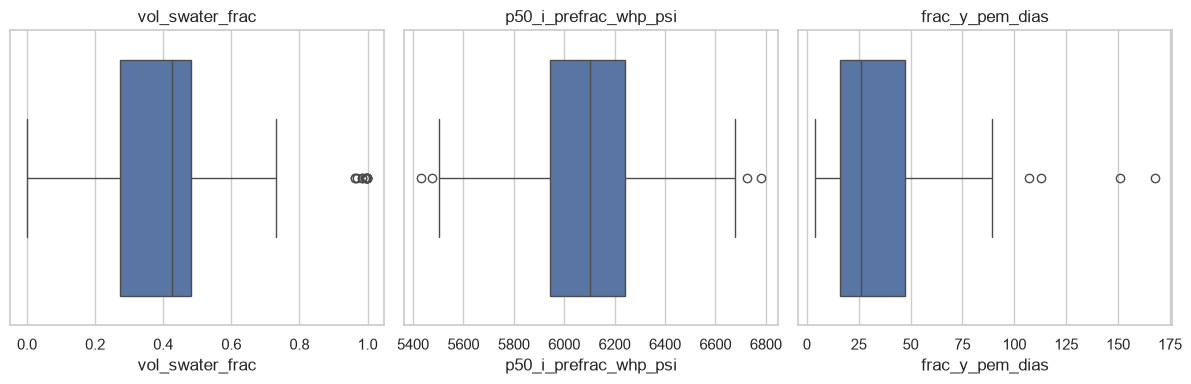

In [21]:
columnas = ['vol_swater_frac', 'p50_i_prefrac_whp_psi', 'frac_y_pem_dias']
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, col in zip(axes, columnas):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

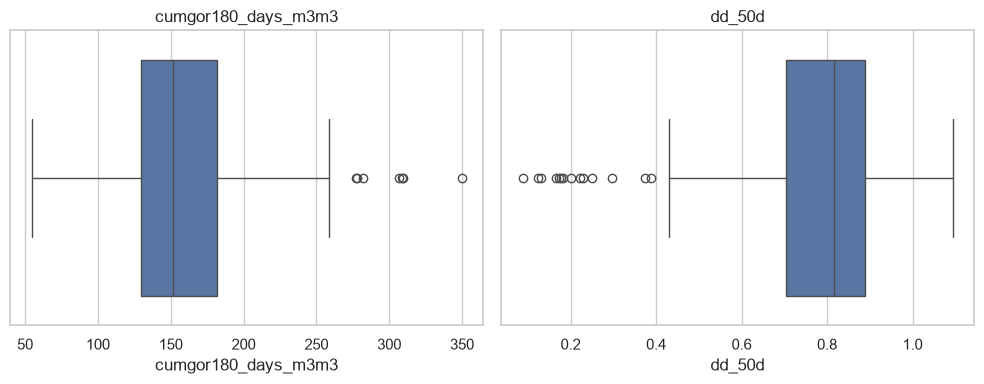

In [22]:

columnas2 = ['cumgor180_days_m3m3', 'dd_50d']
fig, axes = plt.subplots(1, 2, figsize=(10, 4))

for ax, col in zip(axes, columnas2):
    sns.boxplot(x=df[col], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()


Para identificar valores atípicos se utilizó el criterio del rango intercuartílico (IQR): un valor se considera atípico si queda fuera del intervalo [Q1 − 1,5·RIC, Q3 + 1,5·RIC]. Se eligió este criterio porque no supone una distribución normal, supuesto que no se cumple en varias variables (ver punto 7).

| Variable | Atípicos | Ubicación | Observación |
|---|---|---|---|
| `vol_swater_frac` | 12 | Cola superior | Pozos con casi solo slickwater. Son el grupo analizado en el EDA. |
| `dd_50d` | 14 | Cola inferior | Variable excluida del modelo por ser posterior a la producción. |
| `cumgor180_days_m3m3` | 7 | Cola superior | Variable excluida del modelo por ser posterior a la producción. |
| `frac_y_pem_dias` | 4 | Cola superior | Variable excluida del modelo por ser posterior a la producción. |
| `p50_i_prefrac_whp_psi` | 4 | Ambas colas | Presiones previas a la fractura. |

En total hay 41 valores atípicos en 5 variables. Un mismo pozo puede aparecer en más de una variable.

Estos valores se conservan. No hay evidencia en el dataset de que sean errores de carga: no son negativos donde no corresponde, las fracciones de volumen están dentro de [0, 1] y los tiempos son positivos. Por eso se clasifican como **valores válidos pero poco frecuentes**, no como datos incorrectos. Eliminarlos reduciría la información de los pozos de mayor producción, que es justamente el fenómeno que se quiere estudiar.

Esta decisión es provisional. Los valores más alejados, como los de `frac_y_pem_dias`, deberían confirmarse con el área técnica. Además, `dd_50d` y `cumgor180_days_m3m3` no forman parte del modelo, por lo que sus atípicos no afectan la predicción, pero sí importan para la calidad de datos. Si en la etapa de modelado los atípicos resultan influyentes, se podrán evaluar transformaciones o modelos menos sensibles a valores extremos.

### Encoding

In [23]:
# One-Hot Encoding de la variable categórica 'zona'
# drop='first' usa Zona A como categoría de referencia
oh_encoder = OneHotEncoder(drop='first', sparse_output=False)
zona_codificada = oh_encoder.fit_transform(df[['zona']])

# Nombres de las columnas en minúscula: zona_b, zona_c, zona_d
# categories_[0] contiene ['Zona A', 'Zona B', 'Zona C', 'Zona D']; [1:] omite la referencia
nombres_zona = [f"zona_{cat.split()[-1].lower()}" for cat in oh_encoder.categories_[0][1:]]

# Reemplazo 'zona' por sus columnas binarias
zonas_dummies = pd.DataFrame(zona_codificada, columns=nombres_zona, index=df.index).astype(int)
df = pd.concat([df.drop(columns='zona'), zonas_dummies], axis=1)

print(df.columns.tolist())
print(df[nombres_zona].sum())

['tvd_landing', 'ef_l_m', 'm_100_frac', 'vol_swater_frac', 'vol_xlink_frac', 'p50_i_prefrac_whp_psi', '210d_kbbl', 'dias_efectivos', 'frac_y_pem_dias', 'cumgor180_days_m3m3', 'ai_jifi_', 'ild_avg', 'sat', 'omphi_', 'dd_50d', 'zona_b', 'zona_c', 'zona_d']
zona_b    106
zona_c     12
zona_d     22
dtype: int64


In [24]:
df.head(3)

,tvd_landing,ef_l_m,m_100_frac,vol_swater_frac,vol_xlink_frac,p50_i_prefrac_whp_psi,210d_kbbl,dias_efectivos,frac_y_pem_dias,cumgor180_days_m3m3,ai_jifi_,ild_avg,sat,omphi_,dd_50d,zona_b,zona_c,zona_d
0,3114.79,1860.0,0.748826,0.519440,0.0,6206.5,155.521252,1145.0,47.177778,121.7,7072.657427,144.510823,0.176144,0.073696,0.830962,1,0,0
1,3124.09,2460.0,0.740660,0.498118,0.0,6214.0,254.031469,1115.0,43.773611,121.6,7062.238177,105.029498,0.206746,0.066866,0.843503,0,0,0
2,3056.85,2368.0,0.787669,0.519240,0.0,5880.0,178.063669,861.0,54.831250,240.8,7251.706503,56.148262,0.315294,0.074453,0.911041,0,0,1



La variable `zona` es nominal: identifica el bloque operativo del pozo y no tiene un orden natural. Para incluirla en el modelo se utilizó **One-Hot Encoding** con `OneHotEncoder` de scikit-learn.

#### Cómo funciona

Cada categoría se transforma en una columna binaria, con valor 1 si el pozo pertenece a esa zona y 0 en caso contrario. Con `drop='first'` se elimina una categoría como referencia. Se tomó `Zona A`, la primera en orden alfabético, por lo que las columnas resultantes son:

| Zona | `zona_b` | `zona_c` | `zona_d` |
|---|:---:|:---:|:---:|
| Zona A (referencia) | 0 | 0 | 0 |
| Zona B | 1 | 0 | 0 |
| Zona C | 0 | 1 | 0 |
| Zona D | 0 | 0 | 1 |

Eliminar una categoría evita la **trampa de las variables dummy**: si se incluyeran las cuatro columnas junto con el intercepto, su suma sería siempre 1 y la matriz de diseño tendría colinealidad perfecta.

#### Por qué One-Hot Encoding

Se evaluaron cuatro alternativas:

- **`pd.get_dummies`:** produce la misma codificación para los datos disponibles, pero no aprende las categorías del entrenamiento. Cada lote genera sus propias columnas, por lo que la codificación de datos futuros puede no coincidir con la del modelo sin que el código lo advierta.
- **Label Encoding:** asigna un entero a cada zona (0, 1, 2, 3). Esto introduce un orden y una distancia que no existen: un modelo lineal interpretaría `Zona D` como "tres veces" `Zona B`. Está pensado para etiquetas de la variable objetivo, no para predictores nominales.
- **Binning (discretización):** agrupa valores numéricos en intervalos. No aplica a `zona`, que ya es categórica, y crear agrupaciones artificiales implicaría perder información.
- **One-Hot Encoding con `OneHotEncoder`:** representa cada zona sin imponer orden, y aprende las categorías durante el ajuste. Esto permite aplicar la misma codificación a datos nuevos, algo que el proyecto necesita para predicciones futuras.

#### Consideraciones

`OneHotEncoder` usa `handle_unknown='error'` por defecto: si aparece una zona que no estaba en el entrenamiento, la codificación se detiene con un error en lugar de asignar valores de forma silenciosa.

El encoder se ajusta sobre el conjunto de datos disponible. En la sección de modelado, la codificación se integrará en un `Pipeline` para que se ajuste solo con los datos de entrenamiento de cada fold.

Los conteos por zona son: `Zona A` 86 pozos, `Zona B` 106, `Zona C` 12 y `Zona D` 22.

### Inconsistencia entre columnas y Formatos No estandarizados

Para este analisis voy a trabajar con las columnas "vol_swater_frac" y "vol_xlink_frac"

Los pozos que no tengan swater deben tener crosslinker o viceversa. Esto es por una razon de ingenieria a la hora de realizar una estimulacion hidraulica por lo que necesito hacer este cruce para ver si existe alguna inconsistencia respecto a estoy ver si los datos son correctos


In [25]:
cols_fluidos = ['vol_swater_frac', 'vol_xlink_frac']

# 1) Nulos: se cuentan antes de cualquier relleno
print("Nulos:\n", df[cols_fluidos].isna().sum())

# 2) Negativos: un volumen no puede ser menor que cero
print("Negativos:\n", (df[cols_fluidos] < 0).sum())

# 3) Presencia de cada fluido (volumen mayor que cero).
# Nota: NaN > 0 da False, por eso el paso 1 es necesario para interpretar esta columna
swater_usado = df['vol_swater_frac'] > 0
xlink_usado = df['vol_xlink_frac'] > 0

# 4) Tabla de combinaciones
print(pd.crosstab(swater_usado, xlink_usado,
                  rownames=['swater'], colnames=['xlink']))

# 5) Pozos sin ningún fluido (incumple la regla "al menos uno")
print("Pozos sin ningún fluido:", (~swater_usado & ~xlink_usado).sum())

# 6) Pozos con ambos fluidos (candidatos a revisar según el diccionario)
print("Pozos con ambos fluidos:", (swater_usado & xlink_usado).sum())

Nulos:
 vol_swater_frac    0
vol_xlink_frac     0
dtype: int64
Negativos:
 vol_swater_frac    0
vol_xlink_frac     0
dtype: int64
xlink   False  True 
swater              
False       0      1
True       57    168
Pozos sin ningún fluido: 0
Pozos con ambos fluidos: 168


In [26]:
# Suma de ambas proporciones por pozo
suma_fluidos = df['vol_swater_frac'] + df['vol_xlink_frac']

print("Suma mínima:", suma_fluidos.min())
print("Suma máxima:", suma_fluidos.max())

# Referencia: valores máximos individuales, para comparar escala
print(df[['vol_swater_frac', 'vol_xlink_frac']].max())

Suma mínima: 0.06
Suma máxima: 1.0
vol_swater_frac    0.999219
vol_xlink_frac     0.889765
dtype: float64


Se analizó la relación entre `vol_swater_frac` (slickwater) y `vol_xlink_frac` (crosslinker), considerando que un fluido está presente cuando su fracción es mayor que cero.

Ninguna de las dos columnas tiene valores nulos ni negativos. Todos los pozos utilizan al menos uno de los dos fluidos, por lo que la regla de presencia mínima se cumple en los 226 registros. Se identificaron 168 pozos con ambos fluidos, 57 con solo slickwater y 1 con solo crosslinker.


In [27]:
# Verificación de formatos y rangos según las reglas de gobernanza

# 1) Fracciones: deben estar en [0, 1], con tolerancia de 1e-4 por redondeo
fracciones = ['m_100_frac', 'vol_swater_frac', 'vol_xlink_frac', 'sat', 'omphi_']
TOL = 1e-4

resumen_fracciones = pd.DataFrame({
    'minimo': df[fracciones].min(),
    'maximo': df[fracciones].max(),
    'fuera_de_rango': [
        int(((df[c] < -TOL) | (df[c] > 1 + TOL)).sum()) for c in fracciones
    ],
}).round(6)
print("Fracciones (rango esperado [0, 1]):")
print(resumen_fracciones.to_string())

# 2) Variables que deben ser estrictamente positivas
positivas = ['tvd_landing', 'ef_l_m', 'p50_i_prefrac_whp_psi', '210d_kbbl',
             'dias_efectivos', 'frac_y_pem_dias', 'cumgor180_days_m3m3',
             'ai_jifi_', 'ild_avg']
no_positivos = {c: int((df[c] <= 0).sum()) for c in positivas}
print("\nValores no positivos por variable (esperado: 0):")
print(pd.Series(no_positivos).to_string())

# 3) dd_50d: rango observado frente al límite propuesto en la gobernanza
print("\ndd_50d: rango observado")
print(f"minimo = {df['dd_50d'].min():.3f} | maximo = {df['dd_50d'].max():.3f}")
print(f"registros por encima de 1: {int((df['dd_50d'] > 1).sum())}")

# 4) Separador decimal: los valores deben ser float (no texto)
print("\nTipos de las variables numéricas:")
print(df.select_dtypes(include='number').dtypes.value_counts().to_string())

Fracciones (rango esperado [0, 1]):
                   minimo    maximo  fuera_de_rango
m_100_frac       0.062100  1.000002               0
vol_swater_frac  0.000000  0.999219               0
vol_xlink_frac   0.000000  0.889765               0
sat              0.161101  0.570928               0
omphi_           0.037664  0.101729               0

Valores no positivos por variable (esperado: 0):
tvd_landing              0
ef_l_m                   0
p50_i_prefrac_whp_psi    0
210d_kbbl                0
dias_efectivos           0
frac_y_pem_dias          0
cumgor180_days_m3m3      0
ai_jifi_                 0
ild_avg                  0

dd_50d: rango observado
minimo = 0.087 | maximo = 1.093
registros por encima de 1: 4

Tipos de las variables numéricas:
float64    15
int64       3


In [28]:
# Vista general: mínimo y máximo de todas las variables
df.describe().T[['min', 'max']]

,min,max
tvd_landing,2934.600000,3250.320000
ef_l_m,298.800000,3328.000000
m_100_frac,0.062100,1.000002
vol_swater_frac,0.000000,0.999219
vol_xlink_frac,0.000000,0.889765
p50_i_prefrac_whp_psi,5432.000000,6782.000000
210d_kbbl,31.727292,303.812580
dias_efectivos,382.000000,2926.000000
frac_y_pem_dias,4.000000,168.000000
cumgor180_days_m3m3,54.400000,349.600000



Para verificar que las variables estén en el formato y el rango esperados se usaron dos métodos complementarios.

#### Revisión visual

Como el diccionario de datos documenta la unidad y el significado de cada variable, es posible establecer de antemano el rango que puede tomar cada una. Con `df.describe().T` se comparan los mínimos y máximos observados contra ese rango. Esta revisión es rápida y permite detectar a simple vista errores de escala, como fracciones cargadas en porcentaje (máximos cercanos a 100) o valores negativos donde no corresponden.

#### Revisión por reglas

Para no depender solo de la inspección visual, se implementaron reglas específicas en código que informan automáticamente cuántos valores quedan fuera de rango:

- **Fracciones:** `m_100_frac`, `vol_swater_frac`, `vol_xlink_frac`, `sat` y `omphi_` deben estar en [0, 1], con una tolerancia de 10⁻⁴ por errores de redondeo.
- **Variables positivas:** `tvd_landing`, `ef_l_m`, `p50_i_prefrac_whp_psi`, `210d_kbbl`, `dias_efectivos`, `frac_y_pem_dias`, `cumgor180_days_m3m3`, `ai_jifi_` e `ild_avg` deben ser estrictamente mayores que cero.
- **`dd_50d`:** se compara el rango observado con el límite superior propuesto en la gobernanza (1).

Ambas revisiones se realizaron sobre los 226 pozos del conjunto de trabajo.


## 3. Criterios de Gobernanza de datos


Si este análisis formara parte de un proceso industrial real, sería necesario establecer un marco de gobernanza de datos que garantice la confiabilidad de los modelos predictivos. Se proponen las siguientes políticas y reglas.

**1. Responsabilidad de los datos (*Data Stewardship*).** Las disciplinas operativas (Ingeniería de Reservorios, Perforación y Completación) asumen el rol de *Data Owners*: definen el significado de cada variable y validan su calidad desde el origen. Los cambios en el dataset son aprobados por el *Data Owner* correspondiente en un plazo máximo de 5 días hábiles.

**2. Trazabilidad y linaje de datos.** Un diccionario de metadatos documenta, para cada variable, su unidad, el sistema de origen, la etapa operativa, el responsable y las fechas de medición y de procesamiento. La unidad de las fracciones (fracción o porcentaje) y el método de medición de cada variable deben confirmarse con el área fuente. Por ejemplo, debe confirmarse si `p50_i_prefrac_whp_psi` proviene de sensores en boca de pozo.

**3. Identificador del pozo y disponibilidad temporal.** Cada registro debe tener un identificador único de pozo, asignado por el sistema de origen y conservado en todas las versiones del dataset. Esto permite evitar que un mismo pozo aparezca en distintos *folds*. Además, cada variable debe tener registrada la fecha a partir de la cual está disponible, y un predictor solo se utiliza si está disponible antes del momento de la predicción. Variables como `dias_efectivos`, `cumgor180_days_m3m3`, `dd_50d` y `frac_y_pem_dias` se miden durante la producción y deben revisarse con este criterio.

**4. Control de versiones y seguridad.** Se mantiene un sistema de control de versiones sobre los datasets curados. Cualquier limpieza, imputación o eliminación genera una nueva versión documentada, y los datos crudos originales se conservan sin modificaciones. Se establecen políticas de acceso basadas en roles para proteger los datos sensibles de producción e inversión.

**5. Validación automática (reglas de calidad).** Los controles se ejecutan en el sistema de ingesta, antes de incorporar cada carga al dataset de trabajo. Las reglas concretas son:

* **Estructura del archivo:** las columnas sin nombre y las filas completamente vacías se eliminan en la ingesta, y la cantidad eliminada se registra en el log de carga. En el dataset analizado eran 10 columnas y 772 filas.
* **Zona:** valores categóricos estandarizados con formato "Zona X" (A, B, C, D), sin variantes tipográficas. Una zona nueva no se incorpora automáticamente: requiere validación del responsable antes de reentrenar el modelo.
* **Formato numérico:** `tvd_landing` y `ef_l_m` (nombrada `ef_L_m` en el diccionario) deben ser numéricas, estrictamente positivas y con el punto decimal como único separador.
* **Fracciones:** `m_100_frac`, `vol_swater_frac`, `vol_xlink_frac`, `sat` (`Sat` en el diccionario) y `omphi_` deben estar en el rango [0, 1], con una tolerancia de 10⁻⁴ por errores de redondeo. Los valores fuera de ese rango se reportan. En el dataset analizado todas cumplen la regla, y el máximo de `m_100_frac` (1,000002) está dentro de la tolerancia.
* **Presencia de fluidos:** al menos uno de los dos volúmenes (`vol_swater_frac`, `vol_xlink_frac`) debe ser mayor que cero. Los pozos con ambos fluidos se documentan como hallazgo a validar con el área técnica, sin tratarlos como error de carga. Lo mismo aplica a los pozos con un solo fluido.
* **Presiones:** `p50_i_prefrac_whp_psi` debe ser positiva. El responsable técnico define un rango de referencia para la formación a partir de datos históricos, y los valores fuera de ese rango se reportan para revisión.
* **Producción y tiempos:** `210d_kbbl` (en miles de barriles), `cumgor180_days_m3m3`, `dias_efectivos` y `frac_y_pem_dias` deben ser estrictamente positivas.
* **Otras variables:** `ai_jifi_` (adimensional) e `ild_avg` (ohm·m) deben ser positivas. Para `dd_50d`, el diccionario indica "Días / índice". El rango observado va de 0,087 a 1,093, y 4 registros superan el límite de referencia de 1. Estos casos se revisan con el responsable técnico antes de fijar el límite definitivo.

**6. Tratamiento de valores atípicos.** Los valores atípicos identificados con el criterio IQR se conservan y se marcan en el dataset, sin eliminarlos. Su validación queda a cargo del *Data Owner*. Eliminarlos solo puede hacerse con una justificación técnica documentada en una nueva versión del dataset.

# Parte 2 - Metodologia y Analisis exploratorio

## 4. Variable a predecir

Se seleccionó la variable `210d_kbbl`, que representa la producción acumulada de petróleo a los 210 días de producción, expresada en miles de barriles (kbbl). Es una variable numérica continua, por lo que el problema es de regresión.

La elección se justifica porque el objetivo de una fractura hidráulica es aumentar la producción de petróleo, y la producción a 210 días resume ese desempeño en un horizonte de corto plazo.

### Alcance del modelo

El modelo utiliza el diseño de fractura **ejecutado** (volúmenes de fluidos, arena y longitud de la rama), junto con las condiciones de roca y de presión previas a la fractura. Con este enfoque, el modelo permite:

- Identificar qué características de diseño y de formación se asocian con mayor producción a 210 días.
- Comparar la producción esperada entre condiciones geológicas y de diseño observadas.

No permite decidir el diseño de una fractura antes de ejecutarla, porque el diseño ejecutado no existe en ese momento. Los resultados describen asociaciones y capacidad predictiva, no efectos causales del diseño sobre la producción.

### Características de la variable objetivo

La variable tiene 226 registros completos, sin valores faltantes. Su distribución es asimétrica hacia la derecha (media 127,5 kbbl, mediana 102,6 kbbl, asimetría 0,743), con valores entre 31,7 y 303,8 kbbl. Esta asimetría se considera al evaluar los residuos del modelo.

### Criterio de selección de predictores

Los predictores se eligieron por dos criterios: ser conocidos antes o durante la fractura, es decir, antes de la puesta en producción, y describir condiciones que pueden influir en la producción.

- **Profundidad y geometría del pozo:** `tvd_landing` (profundidad vertical del landing) y `ef_l_m` (longitud efectiva de la rama horizontal). Definen la posición del pozo en el reservorio y el alcance de la estimulación.
- **Diseño de estimulación ejecutado:** `m_100_frac` (suma de porcentajes de arena de malla 100), `vol_swater_frac` (proporción de slickwater) y `vol_xlink_frac` (proporción de fluido crosslinked). Describen cómo se fracturó el pozo y son la decisión operativa que el análisis evalúa.
- **Presión previa a la fractura:** `p50_i_prefrac_whp_psi` (presión de boca de pozo antes de la fractura). Refleja el estado del reservorio antes de la estimulación.
- **Geología y geomecánica estática:** `ai_jifi_`, `ild_avg` (resistividad profunda), `sat` (saturación de fluidos) y `omphi_` (porosidad efectiva). Describen la calidad de la roca, que no depende del diseño de fractura.
- **Zona:** `zona`, variable categórica que identifica el bloque operativo. Se codifica con One-Hot Encoding, usando `Zona A` como categoría de referencia.

En total, el modelo usa 10 variables numéricas y 1 variable categórica, que se transforma en 3 columnas binarias. Son 13 variables de entrada.

### Variables excluidas del modelo

Las siguientes variables no se usan como predictores porque se conocen después de la puesta en producción. Incluirlas introduciría **fuga de información** (*leakage*): el modelo aprendería de datos que contienen el resultado que busca predecir, y su desempeño no reflejaría la capacidad real de predicción.

- **`dias_efectivos`:** días que el pozo produjo efectivamente, sin considerar cierres. Se acumula durante la producción.
- **`dd_50d`:** indicador de declinación a 50 días de producción. Requiere producir 50 días para conocerse.
- **`cumgor180_days_m3m3`:** relación gas-petróleo acumulada a 180 días. Requiere producir 180 días para conocerse.
- **`frac_y_pem_dias`:** días entre la fractura y la puesta en producción. Se conoce recién al iniciar la producción.

### Otras variables descartadas como objetivo

Además, se evaluaron otras variables como posible objetivo y se descartaron por motivos distintos al de la fuga de información:

- `frac_y_pem_dias` mide un intervalo de tiempo entre fractura y producción, no un resultado de producción.
- `zona` es un identificador de bloque operativo, no una medida de desempeño.


In [29]:
objetivo = '210d_kbbl'
print("Registros con objetivo:", df[objetivo].notna().sum(), "de", len(df)) #Aca me fijo que todas las filas tengan la variable objetivo
print("Nulos en objetivo:", df[objetivo].isna().sum()) #Cuantos nulos de la variable objetivo hay
print(df[objetivo].describe()) #Estadísticas descriptivas de la variable objetivo
print("Asimetría:", round(df[objetivo].skew(), 3)) #Medida de asimetría de la variable objetivo

# Relación con las variables de producción, que podrían ser fuga de información
candidatas = ['dias_efectivos', 'cumgor180_days_m3m3', 'dd_50d', 'frac_y_pem_dias']
print(df[[objetivo] + candidatas].corr()[objetivo].round(3)) #Correlación entre la variable objetivo y las variables candidatas

Registros con objetivo: 226 de 226
Nulos en objetivo: 0
count    226.000000
mean     127.487714
std       63.264054
min       31.727292
25%       76.661211
50%      102.565083
75%      172.903248
max      303.812580
Name: 210d_kbbl, dtype: float64
Asimetría: 0.743
210d_kbbl              1.000
dias_efectivos        -0.573
cumgor180_days_m3m3   -0.108
dd_50d                 0.395
frac_y_pem_dias        0.294
Name: 210d_kbbl, dtype: float64


## 5. Clasificación de variables


Las columnas del dataset se clasifican en tres grupos: la variable objetivo, las predictoras que utiliza el modelo y las variables excluidas por corresponder a mediciones posteriores a la puesta en producción. Los nombres corresponden a las columnas normalizadas en el código.

### Variable objetivo

| Variable | Tipo | Descripción |
|---|---|---|
| `210d_kbbl` | Cuantitativa continua | Producción acumulada de petróleo a los 210 días de producción (kbbl) |

### Predictoras numéricas (10)

Según el diccionario de datos, todas son de tipo numérico continuo.

| Variable | Categoría | Descripción | Unidad |
|---|---|---|---|
| `tvd_landing` | Profundidad | Profundidad vertical del landing | m |
| `ef_l_m` | Diseño de estimulación | Longitud efectiva de la rama horizontal | m |
| `m_100_frac` | Diseño de estimulación | Suma de porcentajes de arena de malla 100 | Fracción |
| `vol_swater_frac` | Diseño de estimulación | Proporción de slickwater utilizado en la fractura | Fracción |
| `vol_xlink_frac` | Diseño de estimulación | Proporción de fluido crosslinked utilizado en la fractura | Fracción |
| `p50_i_prefrac_whp_psi` | Diseño de estimulación | Presión de boca de pozo previa a la fractura (percentil 50) | psi |
| `ai_jifi_` | Geomecánica / geología | Atributo geológico de caracterización de roca | Adimensional |
| `ild_avg` | Geología estática | Resistividad profunda promedio | ohm·m |
| `sat` | Geología estática | Saturación de fluidos de la formación | Fracción |
| `omphi_` | Geología estática | Porosidad efectiva media | Fracción |

### Predictora categórica (1)

- **`zona`:** variable nominal con cuatro categorías (`Zona A`, `Zona B`, `Zona C` y `Zona D`). Se codifica con One-Hot Encoding usando `Zona A` como categoría de referencia.

### Variables derivadas

- **`zona_b`, `zona_c` y `zona_d`:** surgen de la variable `zona` mediante One-Hot Encoding con `drop='first'`. Valen 1 si el pozo pertenece a esa zona y 0 en caso contrario. Un pozo de `Zona A` tiene valor 0 en las tres.

No se generaron otras variables derivadas para el modelo. La suma de `vol_swater_frac` y `vol_xlink_frac` se calculó solo para verificar la regla de proporciones y no se incluye como predictor.

### Variables excluidas

Son variables numéricas que se conocen después de la puesta en producción. Se excluyen para evitar fuga de información.

| Variable | Motivo de exclusión |
|---|---|
| `dias_efectivos` | Días produciendo efectivamente; se acumula durante la producción |
| `dd_50d` | Indicador de declinación a 50 días de producción |
| `cumgor180_days_m3m3` | Relación gas-petróleo acumulada a 180 días |
| `frac_y_pem_dias` | Días entre la fractura y la puesta en producción |

En total, el modelo utiliza 10 predictoras numéricas y 3 variables derivadas de `zona`, es decir, 13 variables de entrada.

## 6. Problema de Regresion o Clasificacion

El presente proyecto se define como un problema de **regresión**, ya que la variable objetivo (`210d_kbbl`) es numérica y continua. El objetivo del modelo es estimar el volumen de petróleo producido a los 210 días, expresado en miles de barriles (kbbl), y no asignar cada pozo a una categoría.

Se descartó un enfoque de clasificación como definición del problema. Una alternativa habría sido transformar la variable en categorías, por ejemplo, pozos de alta y baja productividad según un umbral. Esa transformación reduce la información disponible: dos pozos con valores de 100 y 290 kbbl quedarían en la misma categoría si ambos superan el umbral. Además, obliga a fijar un corte arbitrario. Por eso se mantiene la regresión, que estima directamente el volumen esperado.

Como medida complementaria, en las secciones de evaluación se utiliza la mediana de entrenamiento como umbral para calcular accuracy, F1 y matriz de confusión. Esto permite interpretar el desempeño en términos de alta o baja productividad, sin que ese corte defina el problema.

El modelo utiliza como predictores las 10 variables numéricas y las 3 columnas binarias derivadas de `zona` (`zona_b`, `zona_c` y `zona_d`), descritas en el punto 5. Las variables posteriores a la puesta en producción quedan excluidas por fuga de información, según lo explicado en el punto 4.

El desempeño como problema de regresión se evalúa con MAE, RMSE y R². MAE y RMSE se expresan en kbbl, la misma unidad de la variable objetivo. R² es adimensional y mide la proporción de variabilidad explicada por el modelo.

## 7. Medidas de tendencia Central y de dispersion

### Analisis de la tendencia 

In [30]:
#Veo nuevamente las medidas de tendencia central y dispersión para ver si hay algo raro en los datos
df.describe().T

,count,mean,std,min,25%,50%,75%,max
tvd_landing,226.0,3085.735885,73.550337,2934.600000,3027.237500,3083.475000,3132.257500,3250.320000
ef_l_m,226.0,1759.787696,566.585128,298.800000,1322.512500,1739.687500,2252.531250,3328.000000
m_100_frac,226.0,0.371677,0.312043,0.062100,0.136300,0.186150,0.748304,1.000002
vol_swater_frac,226.0,0.413099,0.186202,0.000000,0.272871,0.427009,0.482266,0.999219
vol_xlink_frac,226.0,0.284571,0.261738,0.000000,0.000195,0.204569,0.580064,0.889765
p50_i_prefrac_whp_psi,226.0,6094.205752,240.052690,5432.000000,5941.500000,6101.500000,6240.750000,6782.000000
210d_kbbl,226.0,127.487714,63.264054,31.727292,76.661211,102.565083,172.903248,303.812580
dias_efectivos,226.0,1754.358407,604.786486,382.000000,1317.250000,1793.500000,2205.500000,2926.000000
frac_y_pem_dias,226.0,33.909999,24.427098,4.000000,16.000000,26.235417,47.133333,168.000000
cumgor180_days_m3m3,226.0,158.796903,45.469661,54.400000,129.325000,151.200000,181.625000,349.600000


In [31]:
objetivo = '210d_kbbl'
predictoras_modelo = [
    'tvd_landing', 'ef_l_m', 'm_100_frac', 'vol_swater_frac', 'vol_xlink_frac',
    'p50_i_prefrac_whp_psi', 'ai_jifi_', 'ild_avg', 'sat', 'omphi_'
]
# Verificación: deben ser 10 predictoras y todas existir en el DataFrame
assert len(predictoras_modelo) == 10
assert all(c in df.columns for c in predictoras_modelo + [objetivo])

cols = predictoras_modelo + [objetivo]

# Forma de la distribución: asimetría y curtosis en exceso (la normal vale 0)
forma = pd.DataFrame({
    'asimetria': df[cols].skew(),
    'curtosis_exceso': df[cols].kurt(),
}).round(3).sort_values('asimetria')

print(forma.to_string())

                       asimetria  curtosis_exceso
ai_jifi_                  -0.037           -0.824
p50_i_prefrac_whp_psi      0.011            0.212
tvd_landing                0.091           -0.760
ef_l_m                     0.210           -0.471
vol_xlink_frac             0.442           -1.354
sat                        0.535           -0.838
ild_avg                    0.657           -0.361
omphi_                     0.676           -0.315
210d_kbbl                  0.743           -0.552
m_100_frac                 0.835           -1.004
vol_swater_frac            1.210            2.716


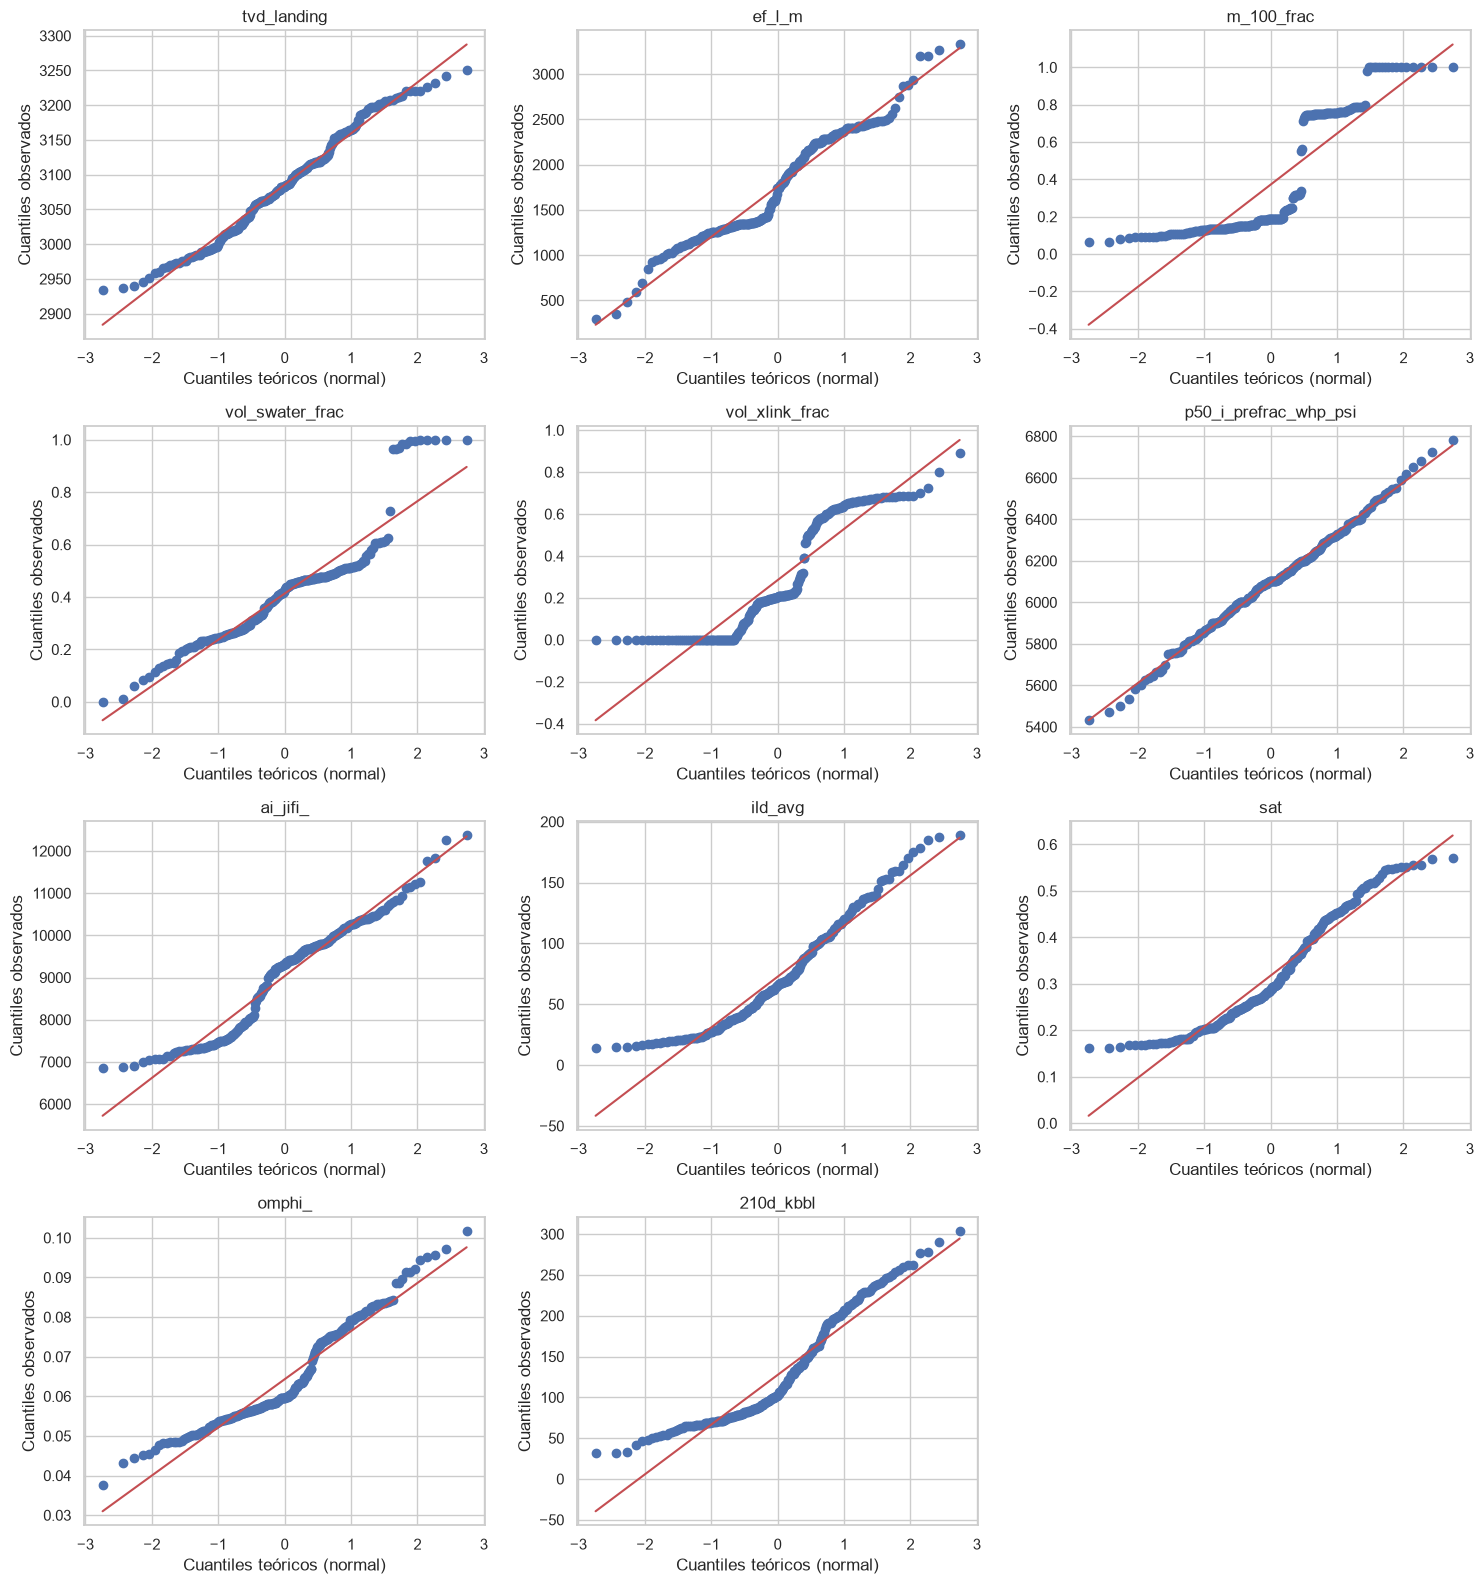

In [32]:


# Variables del modelo + objetivo (los mismos nombres que en la tabla del punto 7)
cols_qq = [
    'tvd_landing', 'ef_l_m', 'm_100_frac', 'vol_swater_frac', 'vol_xlink_frac',
    'p50_i_prefrac_whp_psi', 'ai_jifi_', 'ild_avg', 'sat', 'omphi_', '210d_kbbl'
]
assert all(c in df.columns for c in cols_qq), "Revisá los nombres de columna"

n_cols = 3
n_rows = math.ceil(len(cols_qq) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, cols_qq):
    valores = df[col].dropna()
    stats.probplot(valores, dist='norm', plot=ax)
    ax.set_title(col)
    ax.set_xlabel('Cuantiles teóricos (normal)')
    ax.set_ylabel('Cuantiles observados')

# Oculta los paneles sobrantes (11 variables en una grilla de 3 columnas)
for ax in axes[len(cols_qq):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()



### Gráficos Q-Q frente a la distribución normal

Un gráfico Q-Q compara los cuantiles observados de cada variable con los de una normal. Si los puntos siguen la recta, la distribución es aproximadamente normal. Las desviaciones se leen así:

- **Curvatura o colas que se separan de la recta:** asimetría o colas más pesadas que la normal.
- **Tramo horizontal:** muchos valores repetidos o concentrados (por ejemplo, ceros).
- **Tramo muy empinado:** hueco en los datos, es decir, un rango con pocos pozos.

Las variables se agrupan según el tipo de desviación observada.

**Cercanas a la normal.** `p50_i_prefrac_whp_psi` tiene el mejor ajuste del conjunto. `tvd_landing` sigue la recta en el centro y solo se aparta en los extremos.

**Con huecos en el centro.** `ef_l_m` sigue la recta en el tramo central, pero tiene un hueco entre 1.500 y 2.000 m aproximadamente, y su extremo superior queda por encima de la recta, lo que indica una cola hacia la derecha. Coincide con la distribución bimodal del histograma. `ai_jifi_` tiene forma de S: aunque su asimetría es casi nula (−0,037), ambos extremos se apartan de la recta y hay un hueco alrededor de 8.000 a 9.000. Esto muestra que la asimetría promedio no capta todas las desviaciones de la normalidad.

**Con grupos separados.** `m_100_frac` es la variable con desviaciones más marcadas. Se distinguen tres niveles: valores bajos entre 0,06 y 0,35, con una meseta entre 0,1 y 0,2; un grupo intermedio cerca de 0,7 a 0,8, y un grupo cerca de 1,0. Entre el primer y el segundo nivel hay un hueco. El Q-Q sugiere que el grupo alto se divide en dos niveles, lo que conviene confirmar en el histograma de la sección 8, porque hasta ahora describimos dos grupos.

`vol_swater_frac` sigue la recta en el centro. Su cola superior tiene un grupo de unos 12 pozos con valores cercanos a 1,0, y hay un punto aislado alrededor de 0,73. En el extremo inferior hay pozos sin slickwater.

`vol_xlink_frac` tiene un tramo horizontal en 0. Corresponde a unos 57 pozos, es decir, alrededor del 25 % del conjunto, que no usan crosslinker. Después hay un hueco entre 0,2 y 0,4, y la cola superior llega a valores cercanos a 0,9.

**Con cola hacia la derecha.** `210d_kbbl`, `ild_avg`, `sat` y `omphi_` tienen los valores bajos agrupados por encima de la recta, lo que indica una cola inferior comprimida, y los valores altos se apartan hacia arriba. Esto es un patrón de asimetría positiva. En `ild_avg` la mayor desviación está en el extremo inferior, no en el superior.


### Clasificación de las variables según su asimetría

Se usó como referencia orientativa el rango de asimetría: valores entre −0,5 y 0,5 corresponden a distribuciones aproximadamente simétricas, y valores por fuera de ese rango indican asimetría. Cuando el valor absoluto supera 1, la asimetría se considera fuerte.

**Aproximadamente simétricas (|asimetría| < 0,5):**

- `ai_jifi_` (−0,037)
- `p50_i_prefrac_whp_psi` (0,011)
- `tvd_landing` (0,091)
- `ef_l_m` (0,210)
- `vol_xlink_frac` (0,442)

**Asimétricas hacia la derecha (asimetría entre 0,5 y 1):**

- `sat` (0,535)
- `ild_avg` (0,657)
- `omphi_` (0,676)
- `210d_kbbl` (0,743)
- `m_100_frac` (0,835)

**Fuertemente asimétrica (asimetría mayor a 1):**

- `vol_swater_frac` (1,210)

Ninguna variable tiene asimetría negativa fuerte. La simetría estimada no garantiza normalidad: `ai_jifi_` tiene asimetría casi nula, pero sus colas se apartan de la distribución normal, como se observa en los gráficos Q-Q.

## 8. Graficos de Distribución

### Defino Variables 

In [33]:
# Variables del modelo y objetivo
predictoras_modelo = [
    'tvd_landing', 'ef_l_m', 'm_100_frac', 'vol_swater_frac', 'vol_xlink_frac',
    'p50_i_prefrac_whp_psi', 'ai_jifi_', 'ild_avg', 'sat', 'omphi_'
]
objetivo = '210d_kbbl'
cols_dist = predictoras_modelo + [objetivo]

# Reconstruye la etiqueta de zona a partir de las dummies (Zona A = referencia)
zona_label = np.select(
    [df['zona_b'] == 1, df['zona_c'] == 1, df['zona_d'] == 1],
    ['Zona B', 'Zona C', 'Zona D'],
    default='Zona A'
)
df['zona_label'] = zona_label #Reconstruyo esta columna ya que si no tendriamos error al graficarla.


### 8.1 - Histogramas

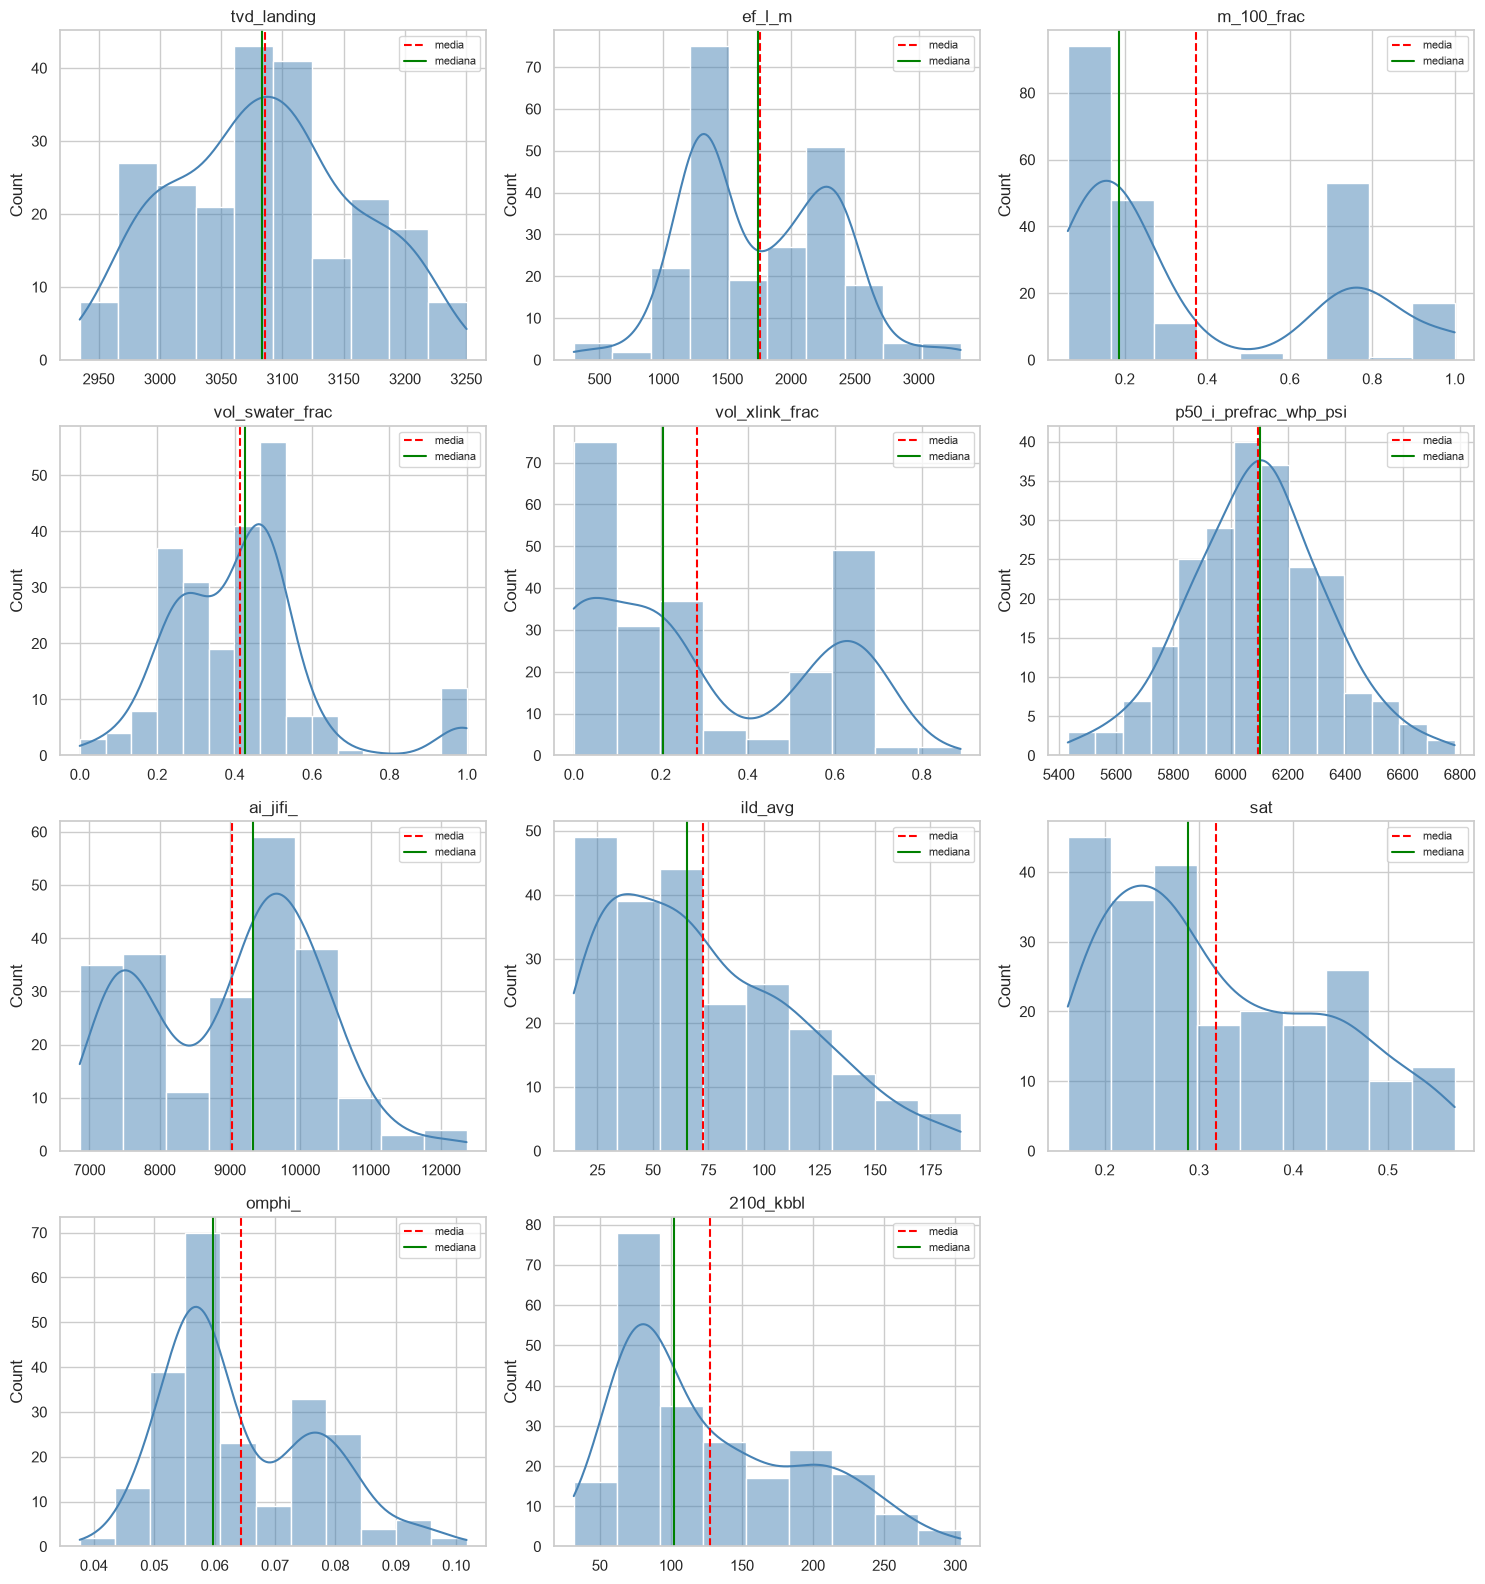

In [34]:

n_cols = 3
n_rows = math.ceil(len(cols_dist) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = axes.flatten()

for ax, col in zip(axes, cols_dist):
    sns.histplot(df[col], bins='auto', kde=True, ax=ax, color='steelblue')
    ax.axvline(df[col].mean(), color='red', linestyle='--', label='media')
    ax.axvline(df[col].median(), color='green', linestyle='-', label='mediana')
    ax.set_title(col)
    ax.set_xlabel('')
    ax.legend(fontsize=8)

for ax in axes[len(cols_dist):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()


#### 8.1.1 Comprobación de huecos en la distribución

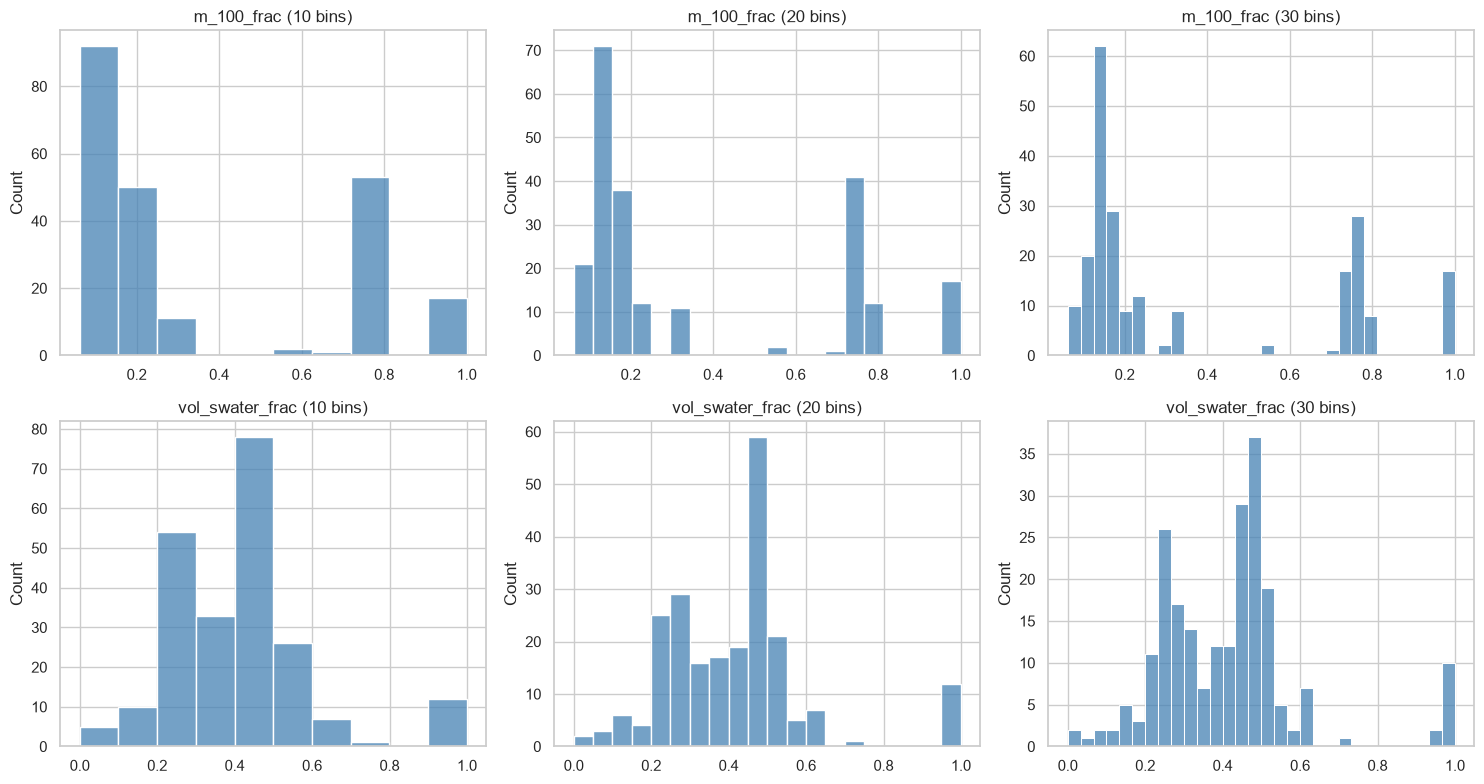

m_100_frac entre 0,4 y 0,7: 2
vol_swater_frac entre 0,65 y 0,95: 1


In [35]:
# Comprobación de huecos: mismos datos, distinto número de bins.
# Un hueco que persiste con 10, 20 y 30 bins es una característica de los datos.
variables_hueco = ['m_100_frac', 'vol_swater_frac']
bins_prueba = [10, 20, 30]

fig, axes = plt.subplots(len(variables_hueco), len(bins_prueba), figsize=(15, 4 * len(variables_hueco)))

for fila, col in zip(axes, variables_hueco):
    for ax, bins in zip(fila, bins_prueba):
        sns.histplot(df[col], bins=bins, kde=False, ax=ax, color='steelblue')
        ax.set_title(f'{col} ({bins} bins)')
        ax.set_xlabel('')

plt.tight_layout()
plt.show()

# Conteo de pozos en los intervalos sin datos. Se usa el mismo corte que en el texto:
# m_100_frac entre 0,4 y 0,7; vol_swater_frac entre 0,65 y 0,95
print("m_100_frac entre 0,4 y 0,7:", int(df['m_100_frac'].between(0.4, 0.7).sum()))
print("vol_swater_frac entre 0,65 y 0,95:", int(df['vol_swater_frac'].between(0.65, 0.95).sum()))

Observamos ciertos huecos en las variables `m_100_frac` y `vol_swater_frac`. 

Para descartar que los huecos observados en los histogramas sean un efecto del número de bins, se graficaron `m_100_frac` y `vol_swater_frac` con 10, 20 y 30 bins, y se contaron los pozos dentro de los intervalos sin datos.

##### Lectura de `m_100_frac`

El hueco entre 0,4 y 0,7 se mantiene con 10, 20 y 30 bins. Con 10 bins aparece como un espacio vacío, y con 20 y 30 se ven los mismos pocos pozos sueltos cerca de 0,55 (una barra de 2 pozos). El conteo confirma que hay 2 pozos en ese intervalo, así que no es un vacío total sino una zona casi sin datos.

Además, los grupos siguen separados: uno entre 0,05 y 0,35, otro entre 0,7 y 0,8 y un tercero cerca de 1,0. Con 30 bins se ve que el grupo alto se parte en dos picos (cerca de 0,75 y de 1,0), lo que es consistente con la observación del gráfico Q-Q de la sección 7.

**Conclusión:** el hueco es real. Hay una zona con 2 pozos en el intervalo, no un efecto del ancho del bin.

##### Lectura de `vol_swater_frac`

El intervalo entre 0,65 y 0,95 tiene 1 pozo, y el hueco aparece con 10 y 20 bins. Con 30 bins se ven puntos aislados cerca de 0,7 y 0,75, que son los que forman el conteo de 1. El grupo cercano a 1,0 queda claramente separado del resto, con unos 12 pozos, lo que coincide con el análisis de valores extremos.

**Conclusión:** el hueco es real. El grupo de alto slickwater está separado del pico principal, pero hay muy pocos pozos entre ambos.

### 8.2 - Relacion entre variables predictoras

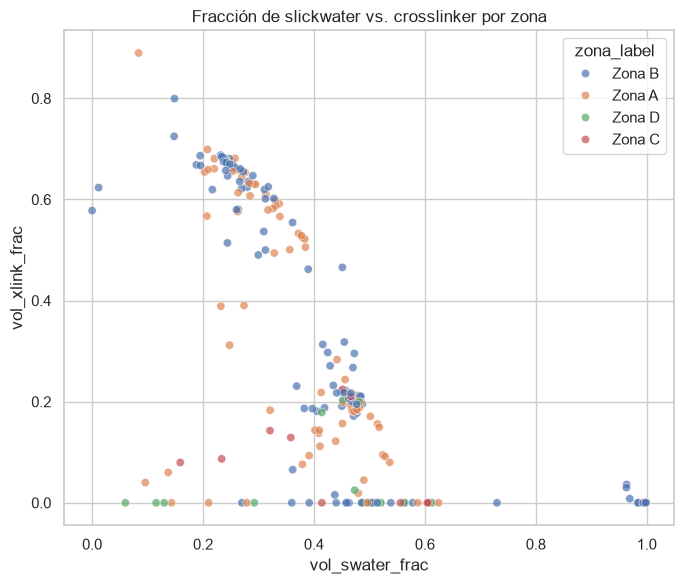

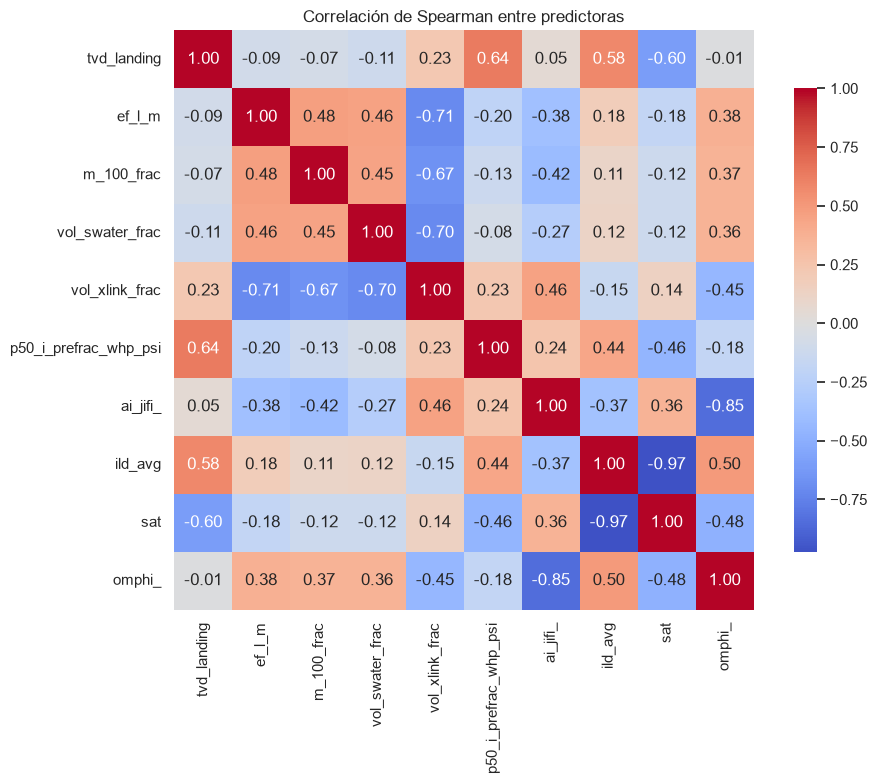

In [36]:
fig, ax = plt.subplots(figsize=(7, 6))
sns.scatterplot(data=df, x='vol_swater_frac', y='vol_xlink_frac',
                hue='zona_label', alpha=0.7, ax=ax)
ax.set_title('Fracción de slickwater vs. crosslinker por zona')
ax.set_xlabel('vol_swater_frac')
ax.set_ylabel('vol_xlink_frac')
plt.tight_layout()
plt.show()

# Matriz de correlación de Spearman entre predictoras (robusta a asimetría y extremos)
# Sirve para detectar colinealidad antes de entrenar el modelo
corr = df[predictoras_modelo].corr(method='spearman')
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, cbar_kws={'shrink': 0.8}, ax=ax)
ax.set_title('Correlación de Spearman entre predictoras')
plt.tight_layout()
plt.show()



Esta sección busca detectar relaciones entre predictoras que puedan afectar la interpretación del modelo. Dos variables que miden casi lo mismo, o que se mueven juntas, aportan información redundante. Esto importa en regresión lineal, donde puede volver inestables los coeficientes.

**Relación entre slickwater y crosslinker.** El gráfico de dispersión muestra una relación negativa entre `vol_swater_frac` y `vol_xlink_frac`: a mayor fracción de slickwater, menor fracción de crosslinker. Se distinguen tres agrupamientos: pozos con slickwater bajo y crosslinker alto (entre 0,6 y 0,8), pozos con slickwater medio (0,4 a 0,5) y crosslinker cercano a 0,2, y el grupo de unos 12 pozos con slickwater cercano a 1,0 y sin crosslinker. La mayoría de los pozos queda por debajo de la recta de suma igual a 1, por lo que las dos fracciones no representan un volumen total fijo. Las zonas aparecen mezcladas en toda la distribución, sin una separación clara por bloque.

**Matriz de correlación de Spearman.** Se usó el coeficiente de Spearman porque no supone linealidad ni normalidad y es robusto a valores extremos. La matriz incluye las 10 predictoras del modelo y excluye el objetivo, porque el objetivo no es una predictora. Cada celda indica la correlación de rangos entre dos variables, entre −1 y 1. Los valores cercanos a ±1 indican información redundante. Como guía de lectura, se consideran de interés las correlaciones con valor absoluto mayor o igual a 0,5; no es un criterio formal de eliminación. Las relaciones más fuertes son:

| Par de variables | Correlación de Spearman |
|---|---|
| `ild_avg` y `sat` | −0,97 |
| `ai_jifi_` y `omphi_` | −0,85 |
| `vol_xlink_frac` y `ef_l_m` | −0,71 |
| `vol_xlink_frac` y `vol_swater_frac` | −0,70 |
| `vol_xlink_frac` y `m_100_frac` | −0,67 |
| `tvd_landing` y `p50_i_prefrac_whp_psi` | 0,64 |
| `tvd_landing` y `sat` | −0,60 |
| `tvd_landing` y `ild_avg` | 0,58 |

Las correlaciones de `ild_avg` con `sat` y de `ai_jifi_` con `omphi_` son muy altas, por lo que estas variables aportan información casi redundante.


### 8.3 - Relacion entre variable predictora y Objetivo

Pregunta: ¿La produccion a 210 dias cambia segun la zona y la longitud de rama?

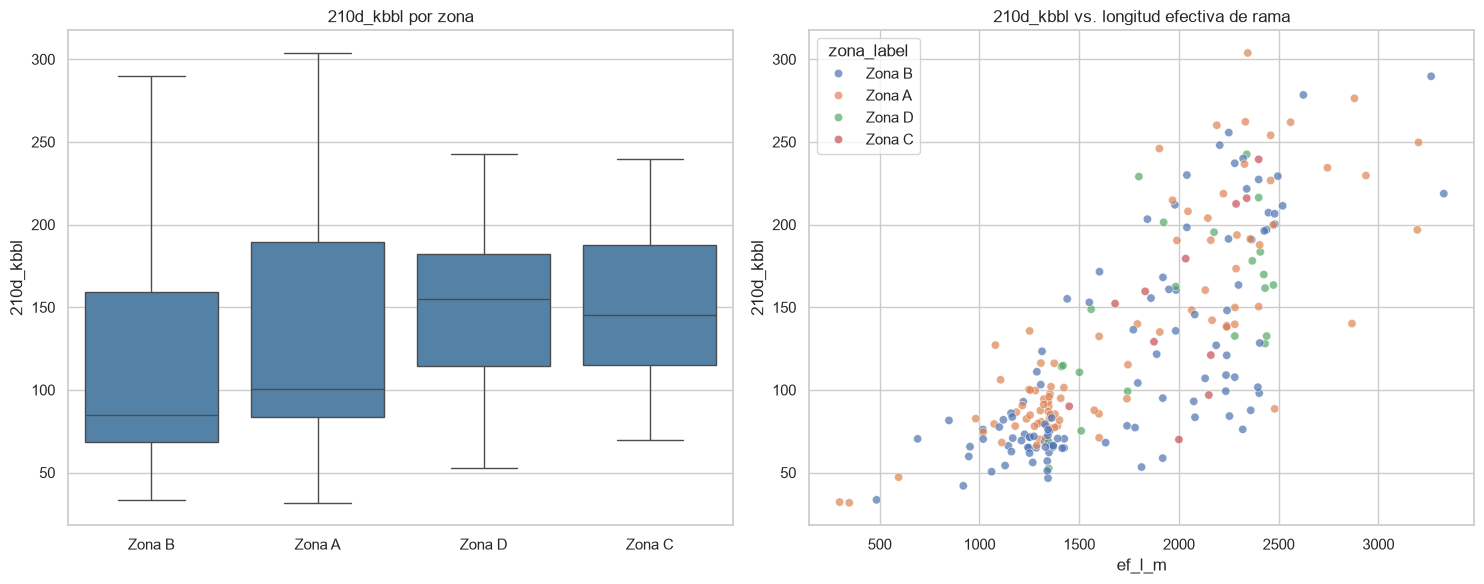

In [40]:

fig, axes = plt.subplots(1, 2, figsize=(15, 6))

sns.boxplot(data=df, x='zona_label', y=objetivo, ax=axes[0], color='steelblue')
axes[0].set_title('210d_kbbl por zona')
axes[0].set_xlabel('')

sns.scatterplot(data=df, x='ef_l_m', y=objetivo, hue='zona_label', alpha=0.7, ax=axes[1])
axes[1].set_title('210d_kbbl vs. longitud efectiva de rama')
axes[1].set_xlabel('ef_l_m')

plt.tight_layout()
plt.show()


In [41]:

# Medianas por sextil de ef_l_m sobre el scatter (muestra la forma de la relación)
sextiles = pd.qcut(df['ef_l_m'], q=6)
medianas = df.groupby(sextiles, observed=True).agg(
    ef=('ef_l_m', 'median'),
    kbbl=(objetivo, 'median'),
)
axes[1].plot(medianas['ef'], medianas['kbbl'], 'o-', color='red', label='mediana por sextil')
axes[1].legend(fontsize=8)

print(df.groupby('zona_label')[objetivo].agg(n='count', mediana='median').round(1).to_string())

              n  mediana
zona_label              
Zona A       86    100.8
Zona B      106     85.1
Zona C       12    145.5
Zona D       22    155.2


In [42]:
# Mediana de la longitud efectiva de rama en cada zona
print(df.groupby('zona_label')['ef_l_m'].median().round(0).to_string())

zona_label
Zona A    1404.0
Zona B    1617.0
Zona C    2092.0
Zona D    2080.0


In [43]:
# Terciles de longitud de rama y mediana de 210d_kbbl por zona dentro de cada tercil
df['tercil_ef'] = pd.qcut(df['ef_l_m'], q=3, labels=['rama corta', 'rama media', 'rama larga'])

tabla_control = (
    df.groupby(['tercil_ef', 'zona_label'], observed=True)[objetivo]
      .agg(n='count', mediana='median')
      .round(1)
)
print(tabla_control.to_string())

                        n  mediana
tercil_ef  zona_label             
rama corta Zona A      33     84.8
           Zona B      41     69.3
           Zona D       2     60.6
rama media Zona A      26     99.5
           Zona B      34     99.6
           Zona C       6    140.7
           Zona D       9    114.7
rama larga Zona A      27    199.8
           Zona B      31    196.2
           Zona C       6    175.6
           Zona D      11    169.8



**Pregunta:** ¿la producción a 210 días cambia según la zona y según la longitud efectiva de la rama?

Para responderla se analizaron dos variables: la zona, que es categórica, y la longitud efectiva de la rama (`ef_l_m`), que es continua. Como las zonas no tienen la misma longitud de rama promedio, la comparación entre zonas se revisó dentro de cada tercil de `ef_l_m`.

#### Producción por zona

El boxplot muestra la distribución de `210d_kbbl` en cada zona. Las medianas son de 85,1 kbbl en la Zona B, 100,8 kbbl en la Zona A, 145,5 kbbl en la Zona C y 155,2 kbbl en la Zona D. La Zona B tiene la mediana más baja en el total, y las Zonas C y D las más altas. La Zona A tiene la caja más ancha, es decir, la mayor dispersión central.

El tamaño de los grupos es desigual: la Zona A tiene 86 pozos, la B 106, la C 12 y la D 22. Por eso las medianas de C y D son menos estables que las de A y B.

#### Producción según la longitud de rama

El gráfico de dispersión muestra una relación positiva entre `ef_l_m` y `210d_kbbl`, pero no lineal. Por debajo de 1.500 m la producción se concentra entre 50 y 120 kbbl. A partir de aproximadamente 2.000 m aparecen pozos con producciones de 150 a 300 kbbl. La dispersión dentro de cada tramo es grande, por lo que la longitud de rama explica una parte importante de la producción, pero no toda.

#### Control por longitud de rama

La mediana de `ef_l_m` es de 1.404 m en la Zona A, 1.617 m en la Zona B, 2.092 m en la Zona C y 2.080 m en la Zona D. La composición por longitud es distinta entre zonas, por lo que la diferencia en el total puede deberse en parte a la rama.

Entre la Zona A y la Zona B, la diferencia se concentra en las ramas cortas: 84,8 kbbl frente a 69,3 kbbl. En los terciles de rama media (99,5 y 99,6 kbbl) y larga (199,8 y 196,2 kbbl), las medianas son prácticamente iguales. La menor producción de la Zona B en el total se explica, por lo tanto, sobre todo por su menor producción en ramas cortas.

Las Zonas C y D tienen medianas altas en el total, pero esa diferencia se debe a su composición: la Zona C no tiene pozos de rama corta y la mayoría de la Zona D está en ramas largas. Dentro de cada tercil no presentan una diferencia estable respecto de A y B. Además, varias celdas tienen menos de 5 pozos (Zona D en rama corta, con 2 pozos; Zonas C y D en los demás terciles, con 6 a 11), por lo que sus medianas son orientativas.

#### Respuesta a la pregunta

- **Zona:** en el total, la Zona B tiene la producción más baja y las Zonas C y D las más altas. Una vez controlada la longitud de rama, la zona no muestra un efecto independiente y claro: entre A y B la única diferencia que se sostiene es la de la rama corta.
- **Longitud de rama:** la producción aumenta con `ef_l_m` de forma no lineal, con un salto alrededor de 2.000 m. La longitud explica la mayor parte de las diferencias observadas.

En conclusión, la producción a 210 días depende en mayor medida de la longitud efectiva de la rama que de la zona. 

# Parte 3 - Modelado predictivo
Objetivo: Entrenar, evaluar y comparar modelos predictivos.

## 9. Elegí un modelo predictivo adecuado para el tipo de problema (ej: regresión lineal, k-NN; árbol de decisión).

In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import KFold, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

# Variables de entrada del modelo (puntos 4 y 5)
features = [
    'tvd_landing', 'ef_l_m', 'm_100_frac', 'vol_swater_frac', 'vol_xlink_frac',
    'p50_i_prefrac_whp_psi', 'ai_jifi_', 'ild_avg', 'sat', 'omphi_',
    'zona_Zona B', 'zona_Zona C', 'zona_Zona D'
]
objetivo = '210d_kbbl'
assert all(c in df.columns for c in features + [objetivo])

X = df[features]
y = df[objetivo]

# Validación cruzada: 5 folds, mezclados, con semilla fija para reproducibilidad
cv = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error',
    'r2': 'r2',
}

# Tabla donde se acumulan los resultados de cada celda
resultados = {}

def evaluar(nombre, modelo):
    """Ejecuta la validación cruzada y guarda media y desvío de cada métrica."""
    res = cross_validate(modelo, X, y, cv=cv, scoring=scoring)
    resultados[nombre] = {
        'MAE (media)': -res['test_mae'].mean(),
        'MAE (desvío)': res['test_mae'].std(),
        'RMSE (media)': -res['test_rmse'].mean(),
        'RMSE (desvío)': res['test_rmse'].std(),
        'R² (media)': res['test_r2'].mean(),
        'R² (desvío)': res['test_r2'].std(),
    }
    print(f"{nombre}: MAE = {resultados[nombre]['MAE (media)']:.2f}, "
          f"R² = {resultados[nombre]['R² (media)']:.3f}")

In [ ]:
# Dummy: predice siempre la media del conjunto de entrenamiento.
# Sin hiperparámetros. Es el piso de comparación.
modelo_dummy = DummyRegressor(strategy='mean')
evaluar('Dummy (media)', modelo_dummy)

In [ ]:
# Regresión lineal: las variables se escalan dentro de cada fold
# (el StandardScaler se ajusta solo con los datos de entrenamiento, evitando fuga de información).
# Sin hiperparámetros a optimizar.
modelo_lineal = Pipeline([
    ('escala', StandardScaler()),
    ('lineal', LinearRegression()),
])
evaluar('Regresión lineal', modelo_lineal)

In [ ]:
# Árbol de decisión de regresión, con hiperparámetros fijados a mano:
#   max_depth = 5          -> profundidad máxima del árbol (controla la complejidad)
#   min_samples_leaf = 5   -> mínimo de pozos en cada hoja (evita hojas con muy pocos datos)
# Estos valores se reemplazarán por los optimizados con Optuna o GridSearch.
modelo_arbol = DecisionTreeRegressor(
    max_depth=5,
    min_samples_leaf=5,
    random_state=42,
)
evaluar('Árbol de decisión (prof. 5, hoja 5)', modelo_arbol)

In [ ]:
# Random forest, con hiperparámetros fijados a mano:
#   n_estimators = 200     -> número de árboles del bosque
#   max_depth = 5          -> profundidad máxima de cada árbol
#   min_samples_leaf = 5   -> mínimo de pozos por hoja
#   max_features = 0.5     -> proporción de variables que se consideran en cada división
modelo_bosque = RandomForestRegressor(
    n_estimators=200,
    max_depth=5,
    min_samples_leaf=5,
    max_features=0.5,
    random_state=42,
    n_jobs=-1,
)
evaluar('Random forest (200 árboles, prof. 5, hoja 5, 50% var.)', modelo_bosque)

In [ ]:
tabla_resultados = pd.DataFrame(resultados).T
print(tabla_resultados.round(2).to_string())

### Resultados

Se evaluaron los cuatro modelos con validación cruzada de 5 folds, mezclados y con semilla fija (42). Los hiperparámetros de los árboles son provisorios y se optimizarán en el punto 10.

| Modelo | MAE (kbbl) | RMSE (kbbl) | R² |
|---|---|---|---|
| Dummy (media) | 54.07 ± 1.18 | 63.30 ± 1.95 | −0.02 ± 0.02 |
| Regresión lineal | 24.29 ± 0.68 | 30.10 ± 1.09 | 0.77 ± 0.01 |
| Árbol de decisión (prof. 5, hoja 5) | 24.35 ± 2.15 | 32.35 ± 3.07 | 0.73 ± 0.04 |
| Random forest (200 árboles, prof. 5, hoja 5, 50 % var.) | 22.51 ± 3.31 | 28.84 ± 4.08 | 0.79 ± 0.05 |

Todos los modelos superan ampliamente al Dummy. El Random forest tiene el menor MAE medio (22.51 kbbl), pero su diferencia con la regresión lineal (1.8 kbbl) es menor que su desvío estándar. El árbol de decisión, con los hiperparámetros actuales, no mejora a la regresión lineal en ninguna métrica y tiene mayor variabilidad entre folds.



In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Partición 80/20. Estratificamos por quintiles de la producción para que
# train y test tengan una distribución del objetivo parecida.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=pd.qcut(y, q=5, labels=False),
)

print(f"Train: {len(X_train)} pozos | Test: {len(X_test)} pozos")
print("Media de 210d_kbbl en train:", round(y_train.mean(), 1),
      "| en test:", round(y_test.mean(), 1))
print("Zonas en test:", X_test[['zona_Zona B', 'zona_Zona C', 'zona_Zona D']].sum().to_dict(),
      "(Zona A = resto)")

In [ ]:
def metricas(y_real, y_pred):
    """MAE, RMSE y R² de un conjunto de predicciones."""
    return {
        'MAE': mean_absolute_error(y_real, y_pred),
        'RMSE': np.sqrt(mean_squared_error(y_real, y_pred)),
        'R²': r2_score(y_real, y_pred),
    }

modelos_finales = {
    'Dummy (media)': DummyRegressor(strategy='mean'),
    'Regresión lineal': Pipeline([('escala', StandardScaler()), ('lineal', LinearRegression())]),
    'Árbol (prof. 5, hoja 5)': DecisionTreeRegressor(max_depth=5, min_samples_leaf=5, random_state=42),
    'Random forest (200, prof. 5, hoja 5, 50 %)': RandomForestRegressor(
        n_estimators=200, max_depth=5, min_samples_leaf=5, max_features=0.5,
        random_state=42, n_jobs=-1),
}

filas = []
predicciones = {}
for nombre, modelo in modelos_finales.items():
    m = clone(modelo)                      # modelo nuevo, sin restos de ejecuciones previas
    m.fit(X_train, y_train)                # solo entrenamiento
    pred_train = m.predict(X_train)
    pred_test = m.predict(X_test)          # predicción sobre pozos nunca vistos
    predicciones[nombre] = pred_test

    t_tr = metricas(y_train, pred_train)
    t_te = metricas(y_test, pred_test)
    filas.append({
        'modelo': nombre,
        'MAE train': t_tr['MAE'], 'MAE test': t_te['MAE'],
        'RMSE test': t_te['RMSE'], 'R² train': t_tr['R²'], 'R² test': t_te['R²'],
    })

tabla_test = pd.DataFrame(filas).set_index('modelo')
print(tabla_test.round(2).to_string())

In [ ]:
rng = np.random.default_rng(42)
n_boot = 2000

def ic_diferencia_mae(nombre_a, nombre_b):
    """IC 95 % de MAE(a) - MAE(b) remuestreando los pozos de test."""
    err_a = np.abs(y_test.values - predicciones[nombre_a])
    err_b = np.abs(y_test.values - predicciones[nombre_b])
    n = len(y_test)
    difs = []
    for _ in range(n_boot):
        idx = rng.integers(0, n, n)
        difs.append(err_a[idx].mean() - err_b[idx].mean())
    lo, hi = np.percentile(difs, [2.5, 97.5])
    return round(err_a.mean() - err_b.mean(), 2), round(lo, 2), round(hi, 2)

pares = [
    ('Regresión lineal', 'Árbol (prof. 5, hoja 5)'),
    ('Regresión lineal', 'Random forest (200, prof. 5, hoja 5, 50 %)'),
    ('Árbol (prof. 5, hoja 5)', 'Random forest (200, prof. 5, hoja 5, 50 %)'),
]
for a, b in pares:
    dif, lo, hi = ic_diferencia_mae(a, b)
    print(f"{a} − {b}: diferencia = {dif} kbbl, IC 95 % = [{lo}, {hi}]")

In [ ]:
from sklearn.metrics import classification_report, precision_score, recall_score, f1_score

# Umbral calculado solo con train (evita fuga de información)
umbral = y_train.median()
y_test_bin = (y_test >= umbral).astype(int)
print(f"Umbral (mediana de train): {umbral:.1f} kbbl")
print(f"Pozos de test en clase alta: {y_test_bin.sum()} de {len(y_test_bin)}\n")

# 1) Reporte completo por modelo
for nombre, pred in predicciones.items():
    pred_bin = (pred >= umbral).astype(int)
    print(f"--- {nombre} ---")
    print(classification_report(
        y_test_bin, pred_bin,
        target_names=['baja', 'alta'], zero_division=0,
    ))

# 2) Tabla resumen, solo para la clase alta
filas_clf = []
for nombre, pred in predicciones.items():
    pred_bin = (pred >= umbral).astype(int)
    filas_clf.append({
        'modelo': nombre,
        'precision (alta)': precision_score(y_test_bin, pred_bin, zero_division=0),
        'recall (alta)': recall_score(y_test_bin, pred_bin, zero_division=0),
        'f1 (alta)': f1_score(y_test_bin, pred_bin, zero_division=0),
        'support (alta)': int(y_test_bin.sum()),
    })
tabla_clf = pd.DataFrame(filas_clf).set_index('modelo')
print("\nResumen clase alta:")
print(tabla_clf.round(2).to_string())

#### Métricas complementarias de clasificación

Como métrica complementaria, las predicciones continuas se transformaron en una clasificación binaria (alta o baja productividad) con umbral igual a la mediana de `210d_kbbl` en el conjunto de entrenamiento (102.6 kbbl). El umbral se calculó solo con train para evitar fuga de información y no se usó para entrenar ningún modelo. Las métricas se calcularon sobre los 46 pozos de test, de los cuales 23 son de alta productividad.

| Modelo | Precision (alta) | Recall (alta) | F1 (alta) | Accuracy |
|---|---|---|---|---|
| Dummy (media) | 0.50 | 1.00 | 0.67 | 0.50 |
| Regresión lineal | 0.80 | 0.87 | 0.83 | 0.83 |
| Árbol (prof. 5, hoja 5) | 0.93 | 0.61 | 0.74 | 0.78 |
| Random forest (200, prof. 5, hoja 5, 50 %) | 0.91 | 0.87 | 0.89 | 0.89 |

El Dummy clasifica todos los pozos como alta productividad, porque su predicción (la media de train) supera el umbral. Por eso su recall es 1.00 y su precision es 0.50. El Random forest obtiene el mejor F1 en la clase alta. El árbol con hiperparámetros fijos tiene la precision más alta, pero deja sin detectar 9 de 23 pozos de alta productividad. Con 46 pozos de test, una diferencia de dos o tres pozos cambia las métricas de forma notable, por lo que estas comparaciones son orientativas.

#### Evaluación en conjunto de prueba

Los datos se dividieron en 80 % para entrenamiento (180 pozos) y 20 % para prueba (46 pozos), con estratificación por quintiles de `210d_kbbl` y semilla fija (42). Cada modelo se entrenó solo con el conjunto de entrenamiento y se evaluó una única vez sobre el de prueba.

| Modelo | MAE train | MAE test | RMSE test | R² train | R² test |
|---|---|---|---|---|---|
| Dummy (media) | 54.64 | 51.40 | 56.97 | 0.00 | −0.01 |
| Regresión lineal | 22.46 | 22.66 | 27.60 | 0.81 | 0.76 |
| Árbol (prof. 5, hoja 5) | 15.91 | 25.57 | 35.80 | 0.90 | 0.60 |
| Random forest (200, prof. 5, hoja 5, 50 %) | 15.56 | 22.91 | 30.73 | 0.90 | 0.71 |

Las diferencias de MAE entre modelos se evaluaron con bootstrap pareado sobre los pozos de prueba (2000 remuestreos):

| Comparación | Diferencia de MAE (kbbl) | IC 95 % |
|---|---|---|
| Regresión lineal − Árbol | −2.91 | [−9.44, 3.44] |
| Regresión lineal − Random forest | −0.26 | [−4.57, 3.82] |
| Árbol − Random forest | +2.66 | [−0.78, 5.98] |

Todos los intervalos incluyen 0: no hay diferencias de MAE estadísticamente distinguibles entre los tres modelos con este conjunto de prueba.

La regresión lineal obtiene el menor RMSE y el mayor R² de test entre los modelos no triviales, y empata en MAE con el Random forest. El árbol con hiperparámetros fijos muestra sobreajuste: su MAE de entrenamiento (15.91) es considerablemente menor que el de prueba (25.57). El Random forest también presenta una brecha, aunque menor. La regresión lineal tiene una brecha mínima entre entrenamiento y prueba.

#### Decisión provisional del modelo

Se aplica la regla de selección fijada antes de la evaluación en prueba: menor MAE medio en validación cruzada de 5 folds, y preferencia por el modelo más simple cuando su diferencia está dentro de un desvío estándar. El Random forest tiene el menor MAE de validación cruzada (22.51 ± 3.31), y la regresión lineal (24.29 ± 0.68) queda dentro de ese desvío. Por lo tanto, se elige la **regresión lineal**. El conjunto de prueba confirma esta decisión, pero no fue el criterio para tomarla.

El árbol de decisión no se mantiene como modelo final: tiene el mayor sobreajuste y el peor desempeño en prueba. Se evaluará de nuevo solo si la optimización de hiperparámetros con validación cruzada anidada muestra una mejora de MAE mayor que un desvío estándar frente a la regresión lineal, con un intervalo de bootstrap que no incluya 0. Si no se cumple esta condición, la decisión final se mantiene.

## 10. Hiperparámetros fundamentales de los modelos

### Modelo final: regresión lineal

La regresión lineal de scikit-learn no tiene hiperparámetros fundamentales que requieran optimización. El único parámetro de configuración, `fit_intercept`, se mantiene en `True` para estimar la ordenada al origen. Las variables se escalan con `StandardScaler` dentro del pipeline, de modo que el escalado se ajusta solo con los datos de entrenamiento de cada fold. El escalado no es un hiperparámetro, sino un paso de preprocesamiento.

### Árbol de decisión de regresión

El árbol de decisión tiene dos hiperparámetros que controlan su complejidad y, por lo tanto, su capacidad de generalizar:

| Hiperparámetro | Función | Efecto si aumenta | Efecto si disminuye |
|---|---|---|---|
| `max_depth` | Máximo de niveles de divisiones sucesivas | El árbol captura relaciones más finas, con mayor riesgo de sobreajuste | El árbol es más simple, con mayor riesgo de subajuste |
| `min_samples_leaf` | Mínimo de pozos que debe tener cada hoja | Las hojas son más grandes y las predicciones más estables | Las hojas pueden tener pocos pozos y las predicciones son más variables |

Estos dos hiperparámetros son los fundamentales porque actúan sobre el sobreajuste de forma directa. Con 180 pozos de entrenamiento, un árbol sin restricciones memoriza los datos, como mostró la brecha entre MAE de entrenamiento (15.91) y de prueba (25.57) del árbol con profundidad 5 y hoja 5.

Otros hiperparámetros de `DecisionTreeRegressor`, como `min_samples_split`, `max_features` o `ccp_alpha`, también regulan la complejidad. Se dejan con sus valores por defecto para no ampliar el espacio de búsqueda con parámetros que aportan poco con este tamaño de muestra.

**Valores actuales (fijos, provisorios):** `max_depth = 5` y `min_samples_leaf = 5`.

**Espacio de búsqueda propuesto:**

- `max_depth`: 2, 3, 4, 5, 6, 8, 10 y sin límite (`None`).
- `min_samples_leaf`: 3, 5, 10, 15 y 20.

Con estos valores se evalúan 8 × 5 = 40 combinaciones. La búsqueda se realiza con validación cruzada anidada: el ciclo interno (Optuna o GridSearch, con 5 folds) elige los hiperparámetros sobre los datos de entrenamiento, y el ciclo externo (5 folds) estima el desempeño. El conjunto de prueba no interviene en la búsqueda.

**Criterio de cambio de modelo.** Según lo fijado en el punto 9, el árbol optimizado solo reemplaza a la regresión lineal si su MAE medio de validación cruzada anidada es menor que el de la regresión lineal en más de un desvío estándar, y el intervalo de bootstrap de la diferencia en prueba no incluye 0. Si no se cumple, la decisión final es la regresión lineal.

### Random forest (referencia)

Para el random forest, los hiperparámetros fundamentales son los mismos del árbol (`max_depth` y `min_samples_leaf`), más `max_features`, que controla cuántas variables se consideran en cada división y es lo que hace que los árboles del bosque sean distintos entre sí. El número de árboles (`n_estimators`) se fija en 200, porque aumentarlo mejora poco la estabilidad a partir de cierto punto. Se optimiza solo si el árbol optimizado no alcanza para la comparación final.

In [ ]:
from sklearn.model_selection import GridSearchCV

# Misma partición externa en todas las comparaciones, con semilla fija
cv_ext = KFold(n_splits=5, shuffle=True, random_state=42)
cv_int = KFold(n_splits=5, shuffle=True, random_state=42)

scoring_gs = {
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error',
    'r2': 'r2',
}

# Espacios de búsqueda (los mismos que se definieron en el punto 10)
grid_arbol = {
    'max_depth': [2, 3, 4, 5, 6, 8, 10, None],
    'min_samples_leaf': [3, 5, 10, 15, 20],
}
grid_bosque = {
    'max_depth': [3, 5, 8, None],
    'min_samples_leaf': [3, 5, 10],
    'max_features': [0.33, 0.5, 1.0],
}

def buscador(estimador, grid):
    """GridSearchCV con validación interna de 5 folds, optimizando el MAE."""
    return GridSearchCV(estimador, grid, cv=cv_int, scoring=scoring_gs,
                        refit='mae', n_jobs=-1)

# Ciclo externo: cada modelo se optimiza dentro de cada fold externo
res_lineal = cross_validate(clone(modelo_lineal), X, y, cv=cv_ext, scoring=scoring_gs)
res_arbol = cross_validate(buscador(DecisionTreeRegressor(random_state=42), grid_arbol),
                           X, y, cv=cv_ext, scoring=scoring_gs, return_estimator=True)
res_bosque = cross_validate(buscador(RandomForestRegressor(n_estimators=200, random_state=42), grid_bosque),
                            X, y, cv=cv_ext, scoring=scoring_gs, return_estimator=True)

def resumen_anidado(nombre, res):
    mae = -res['test_mae']
    print(f"{nombre}: MAE = {mae.mean():.2f} ± {mae.std():.2f} | "
          f"RMSE = {(-res['test_rmse']).mean():.2f} | R² = {res['test_r2'].mean():.3f}")
    return mae

mae_lineal = resumen_anidado('Regresión lineal', res_lineal)
mae_arbol = resumen_anidado('Árbol optimizado (anidado)', res_arbol)
mae_bosque = resumen_anidado('Random forest optimizado (anidado)', res_bosque)

# Hiperparámetros elegidos en cada fold externo (muestra si la elección es estable)
for nombre, res in [('Árbol', res_arbol), ('Random forest', res_bosque)]:
    print(f"\n{nombre}: hiperparámetros elegidos por fold")
    for i, est in enumerate(res['estimator'], 1):
        print(f"  fold {i}: {est.best_params_}")

# Criterio del punto 9: el modelo optimizado reemplaza a la lineal solo si su MAE medio
# es menor que el de la lineal en más de un desvío estándar de la lineal.
umbral_dec = mae_lineal.std()
print(f"\nUmbral de decisión: {umbral_dec:.2f} kbbl")
for nombre, mae in [('Árbol', mae_arbol), ('Random forest', mae_bosque)]:
    dif = mae.mean() - mae_lineal.mean()
    cumple = dif < -umbral_dec
    print(f"{nombre} − lineal: {dif:.2f} kbbl -> {'cumple' if cumple else 'no cumple'}")

In [ ]:
# Búsqueda interna solo con el conjunto de entrenamiento
final_arbol = buscador(DecisionTreeRegressor(random_state=42), grid_arbol).fit(X_train, y_train)
final_bosque = buscador(RandomForestRegressor(n_estimators=200, random_state=42), grid_bosque).fit(X_train, y_train)
lineal_final = clone(modelo_lineal).fit(X_train, y_train)

print("Árbol elegido:", final_arbol.best_params_)
print("Random forest elegido:", final_bosque.best_params_)

# Predicciones sobre test (una vez)
predicciones['Regresión lineal'] = lineal_final.predict(X_test)
predicciones['Árbol optimizado'] = final_arbol.predict(X_test)
predicciones['Random forest optimizado'] = final_bosque.predict(X_test)

filas = []
for nombre in ['Regresión lineal', 'Árbol optimizado', 'Random forest optimizado']:
    p = predicciones[nombre]
    filas.append({
        'modelo': nombre,
        'MAE test': mean_absolute_error(y_test, p),
        'RMSE test': np.sqrt(mean_squared_error(y_test, p)),
        'R² test': r2_score(y_test, p),
    })
print(pd.DataFrame(filas).set_index('modelo').round(2).to_string())

# Bootstrap pareado de las diferencias de MAE (usa la función definida en el punto 9)
for a, b in [('Regresión lineal', 'Árbol optimizado'),
             ('Regresión lineal', 'Random forest optimizado')]:
    dif, lo, hi = ic_diferencia_mae(a, b)
    print(f"{a} − {b}: diferencia = {dif} kbbl, IC 95 % = [{lo}, {hi}]")

## 10. Hiperparámetros fundamentales y optimización

### Hiperparámetros evaluados

- **Regresión lineal:** no tiene hiperparámetros fundamentales que optimizar. El escalado con `StandardScaler` se ajusta dentro de cada fold, por lo que no es un hiperparámetro sino un paso de preprocesamiento.
- **Árbol de decisión de regresión:** `max_depth` (profundidad máxima) y `min_samples_leaf` (mínimo de pozos por hoja). Son los dos parámetros que controlan directamente el sobreajuste. El espacio de búsqueda es `max_depth` en {2, 3, 4, 5, 6, 8, 10, sin límite} y `min_samples_leaf` en {3, 5, 10, 15, 20}.
- **Random forest:** `max_depth`, `min_samples_leaf` y `max_features` (proporción de variables consideradas en cada división). El número de árboles se fija en 200. El espacio de búsqueda es `max_depth` en {3, 5, 8, sin límite}, `min_samples_leaf` en {3, 5, 10} y `max_features` en {0.33, 0.5, 1.0}.

### Optimización con validación cruzada anidada

La búsqueda se realizó con validación cruzada anidada. El ciclo interno (GridSearchCV, 5 folds, mezcla con semilla 42) elige los hiperparámetros optimizando el MAE. El ciclo externo (5 folds, misma partición que en el punto 9) mide el desempeño. El conjunto de prueba no participó en la búsqueda.

| Modelo | MAE (kbbl) | RMSE (kbbl) | R² |
|---|---|---|---|
| Regresión lineal | 24.29 ± 0.68 | 30.10 | 0.770 |
| Árbol optimizado | 25.01 ± 2.11 | 33.11 | 0.719 |
| Random forest optimizado | 21.94 ± 3.52 | 28.38 | 0.792 |

Hiperparámetros elegidos por fold externo:

- **Árbol:** profundidad entre 4 y 6, y hoja entre 3 y 10. La elección varía entre folds, por lo que la configuración no es estable.
- **Random forest:** profundidad 8 o sin límite, hoja 3 y `max_features` 0.5 en la mayoría de los folds. La elección es bastante estable.

### Regla de decisión

Antes de ver los resultados se fijó la siguiente regla. Un modelo optimizado reemplaza a la regresión lineal solo si se cumplen dos condiciones: (a) su MAE medio de CV anidada es menor que el de la lineal en más de un desvío estándar de la lineal (0.68 kbbl), y (b) el intervalo de confianza del 95 % del bootstrap pareado sobre el conjunto de prueba no incluye 0.

### Resultados

- **Árbol optimizado:** no cumple (a). Su MAE de CV es 0.72 kbbl mayor que el de la lineal. En test, empeora (MAE 27.11, R² 0.59) y el IC de la diferencia incluye 0.
- **Random forest optimizado:** cumple (a), con una diferencia de −2.34 kbbl en CV. No cumple (b): en test, la diferencia de MAE con la lineal es −0.01 kbbl, con IC 95 % [−4.16, 4.06]. Además, su RMSE (31.01) y su R² (0.70) de test son peores que los de la lineal (27.60 y 0.76).

### Decisión final

Ningún modelo optimizado cumple las dos condiciones de la regla. La decisión final es la **regresión lineal**. Se elige por tener el menor RMSE y el mayor R² en test entre los modelos evaluados, un MAE igual al del random forest dentro del error de estimación, la menor variabilidad entre folds y la mayor interpretabilidad.

El random forest es una alternativa defendible si la prioridad fuera el MAE en validación cruzada, pero su ventaja no se confirma en test. El árbol de decisión no se recomienda: en validación cruzada no supera a la lineal y en test sobreajusta. Como el conjunto de prueba se consultó en los puntos 9 y 10, su valor como estimación independiente es limitado; la decisión se apoya principalmente en la validación cruzada anidada.

## 11. Entrenamiento y comparación de configuraciones

Se compararon siete configuraciones: una regresión lineal como referencia, tres configuraciones de árbol de decisión y tres de random forest. Las configuraciones se eligieron antes de la evaluación, dentro del espacio de búsqueda definido en el punto 10. Cada una se evaluó con validación cruzada de 5 folds, mezclados y con semilla fija (42), usando solo el conjunto de entrenamiento (180 pozos). El conjunto de prueba no participó en esta comparación.

| Configuración | MAE (kbbl) | RMSE (kbbl) | R² |
|---|---|---|---|
| Regresión lineal | 24.13 ± 2.48 | 30.30 ± 2.57 | 0.77 ± 0.05 |
| Árbol A (prof. 3, hoja 10) | 28.36 ± 2.28 | 37.66 ± 3.03 | 0.65 ± 0.08 |
| Árbol B (prof. 5, hoja 5) | 27.77 ± 5.35 | 37.92 ± 6.40 | 0.64 ± 0.12 |
| Árbol C (prof. 8, hoja 3) | 29.29 ± 5.00 | 39.16 ± 5.10 | 0.61 ± 0.12 |
| RF A (prof. 3, hoja 10, 33 % var.) | 25.53 ± 3.29 | 32.95 ± 3.94 | 0.73 ± 0.06 |
| RF B (prof. 5, hoja 5, 50 % var.) | 22.86 ± 3.06 | 29.91 ± 4.11 | 0.78 ± 0.06 |
| RF C (prof. 8, hoja 3, 100 % var.) | 22.63 ± 3.23 | 29.89 ± 3.89 | 0.78 ± 0.07 |

Las métricas se reportan como media ± desvío entre los 5 folds.

### Comparación pareada contra la regresión lineal

Para cada fold se calculó la diferencia de MAE entre la configuración y la lineal. Un valor negativo indica que la configuración es mejor en ese fold.

| Configuración | Diferencia media (kbbl) | Desvío de la diferencia (kbbl) | Folds mejores que la lineal |
|---|---|---|---|
| Árbol A (prof. 3, hoja 10) | +4.23 | 2.54 | 0 de 5 |
| Árbol B (prof. 5, hoja 5) | +3.63 | 5.66 | 1 de 5 |
| Árbol C (prof. 8, hoja 3) | +5.16 | 4.58 | 1 de 5 |
| RF A (prof. 3, hoja 10, 33 % var.) | +1.40 | 2.02 | 2 de 5 |
| RF B (prof. 5, hoja 5, 50 % var.) | −1.27 | 2.11 | 3 de 5 |
| RF C (prof. 8, hoja 3, 100 % var.) | −1.50 | 2.55 | 3 de 5 |

### Lectura

- **Árboles:** en las tres configuraciones el MAE medio es mayor que el de la regresión lineal, y en la mayoría de los folds también. Aumentar la profundidad de 3 a 8 no mejora el error y aumenta la variabilidad entre folds (el desvío del MAE pasa de 2.28 a 5.00). Esto es consistente con sobreajuste: el árbol se ajusta a cada conjunto de entrenamiento de forma distinta.
- **Random forest A:** con profundidad 3 y 33 % de variables, el bosque queda por encima de la lineal, lo que indica que necesita más profundidad o más variables para rendir.
- **Random forest B y C:** son los únicos modelos con diferencia media negativa, de −1.3 y −1.5 kbbl. Sin embargo, ganan a la lineal solo en 3 de 5 folds y la diferencia tiene un desvío similar a su magnitud. La ventaja existe en promedio, pero no es consistente, y es menor que el desvío de la propia lineal (2.48).

### Relación con la decisión del punto 10

Esta comparación confirma la dirección del punto 10: el random forest es la familia con mejor MAE de validación, y los árboles quedan detrás de la regresión lineal. Como la ventaja del random forest no es consistente entre folds, no alcanza para cambiar la decisión, que se basa en la regla fijada en el punto 9 y en el resultado de prueba del punto 10.

La comparación del punto 11 usa solo los 180 pozos de entrenamiento y sus folds, por lo que sus desvíos son distintos de los del punto 10 (226 pozos). El umbral de decisión del punto 10 se calculó con aquella partición y no se recalcula aquí para favorecer a ningún modelo. Con el desvío de la lineal de esta partición (2.48), el random forest tampoco superaría el umbral de CV. Por lo tanto, la decisión final no depende de la partición elegida.

In [ ]:
from sklearn.model_selection import KFold, cross_validate

# 5 folds sobre el conjunto de entrenamiento (la prueba no se toca)
cv5 = KFold(n_splits=5, shuffle=True, random_state=42)
scoring = {
    'mae': 'neg_mean_absolute_error',
    'rmse': 'neg_root_mean_squared_error',
    'r2': 'r2',
}

# Tres configuraciones por familia, tomadas del espacio de búsqueda del punto 10
configuraciones = {
    'Regresión lineal': clone(modelo_lineal),
    'Árbol A (prof. 3, hoja 10)': DecisionTreeRegressor(max_depth=3, min_samples_leaf=10, random_state=42),
    'Árbol B (prof. 5, hoja 5)': DecisionTreeRegressor(max_depth=5, min_samples_leaf=5, random_state=42),
    'Árbol C (prof. 8, hoja 3)': DecisionTreeRegressor(max_depth=8, min_samples_leaf=3, random_state=42),
    'RF A (prof. 3, hoja 10, 33 % var.)': RandomForestRegressor(
        n_estimators=200, max_depth=3, min_samples_leaf=10, max_features=0.33,
        random_state=42, n_jobs=-1),
    'RF B (prof. 5, hoja 5, 50 % var.)': RandomForestRegressor(
        n_estimators=200, max_depth=5, min_samples_leaf=5, max_features=0.5,
        random_state=42, n_jobs=-1),
    'RF C (prof. 8, hoja 3, 100 % var.)': RandomForestRegressor(
        n_estimators=200, max_depth=8, min_samples_leaf=3, max_features=1.0,
        random_state=42, n_jobs=-1),
}

filas = []
mae_por_fold = {}
for nombre, modelo in configuraciones.items():
    res = cross_validate(modelo, X_train, y_train, cv=cv5, scoring=scoring)
    mae = -res['test_mae']
    mae_por_fold[nombre] = mae
    filas.append({
        'configuración': nombre,
        'MAE (media)': mae.mean(),
        'MAE (desvío)': mae.std(),
        'RMSE (media)': (-res['test_rmse']).mean(),
        'RMSE (desvío)': (-res['test_rmse']).std(),
        'R² (media)': res['test_r2'].mean(),
        'R² (desvío)': res['test_r2'].std(),
    })

tabla_cv = pd.DataFrame(filas).set_index('configuración')
print(tabla_cv.round(2).to_string())

In [ ]:
# Para cada configuración: diferencia de MAE con la lineal en cada fold.
# Negativo = la configuración es mejor que la lineal en ese fold.
referencia = mae_por_fold['Regresión lineal']
filas_dif = []
for nombre, mae in mae_por_fold.items():
    if nombre == 'Regresión lineal':
        continue
    difs = mae - referencia          # arrays de 5 valores, misma partición de folds
    filas_dif.append({
        'configuración': nombre,
        'dif. media (kbbl)': difs.mean(),
        'dif. desvío (kbbl)': difs.std(),
        'folds mejores que lineal': int((difs < 0).sum()),
        'de 5 folds': 5,
    })

tabla_dif = pd.DataFrame(filas_dif).set_index('configuración')
print(tabla_dif.round(2).to_string())

Punto 12 - 12. Mostrá métricas de evaluación (Clasificación: accuracy, F1-score, matriz de confusión.
Regresión: MAE, RMSE, R2)

## 12. Métricas de evaluación

La variable objetivo `210d_kbbl` es continua, por lo que el problema es de regresión. Las métricas principales son MAE, RMSE y R². Como métrica complementaria, las predicciones se transformaron en clasificación binaria (alta o baja productividad) con umbral igual a la mediana de entrenamiento (102.6 kbbl), y se reportan accuracy, F1 y matriz de confusión. El modelo final es la regresión lineal, elegida en el punto 10. Las métricas se presentan para ese modelo y, en la sección 9, para el resto de los modelos.

### Métricas de regresión

| Evaluación | MAE (kbbl) | RMSE (kbbl) | R² |
|---|---|---|---|
| Validación cruzada 5×5 (226 pozos, punto 9) | 24.29 ± 0.68 | 30.10 | 0.770 |
| Conjunto de prueba (46 pozos) | 22.66 | 27.60 | 0.764 |

Los valores de validación cruzada son la estimación principal del desempeño, porque se obtuvieron sobre todos los pozos sin usar el conjunto de prueba para seleccionar. El conjunto de prueba confirma la estimación. Sus valores son similares a los de validación cruzada, lo que indica que el modelo generaliza.

**Interpretación en kbbl.** La producción media a 210 días es de 127.5 kbbl y la mediana de 102.6 kbbl. En el conjunto de prueba, el MAE de 22.66 kbbl equivale a un error promedio de cerca del 18 % de la media y del 22.5 % de la mediana. Es decir, en promedio, la predicción de un pozo se aparta unos 23 kbbl de su valor real. El RMSE de 27.60 kbbl es 1.22 veces el MAE, lo que indica que algunos pozos tienen errores mayores que el promedio. El R² de 0.764 significa que el modelo explica cerca del 76 % de la variación de la producción en el conjunto de prueba. Este valor no basta por sí solo para juzgar la utilidad del modelo: el error de unos 23 kbbl en un pozo típico es la medida operativa relevante.

### Métricas complementarias de clasificación

Con umbral de 102.6 kbbl (mediana de entrenamiento), el conjunto de prueba tiene 23 pozos de alta productividad y 23 de baja.

| Métrica | Regresión lineal (prueba) |
|---|---|
| Accuracy | 0.83 |
| F1 (clase alta) | 0.83 |

Matriz de confusión (filas: real; columnas: predicho):

| | Predicho baja | Predicho alta |
|---|---|---|
| **Real baja** | 18 | 5 |
| **Real alta** | 3 | 20 |

El modelo clasifica correctamente 38 de 46 pozos. Los 5 falsos positivos son pozos de baja productividad que el modelo predice como alta. Los 3 falsos negativos son pozos de alta productividad que el modelo predice como baja. Con 46 pozos, una diferencia de uno o dos casos cambia estas métricas, por lo que se interpretan como orientativas.

### Análisis de residuos

Al agrupar los 46 pozos de prueba en cuartiles según su valor real, el error promedio cambia de signo con el nivel de producción. En el cuartil inferior (Q1, valores reales hasta unos 75 kbbl) el error medio es prácticamente nulo (+0.02 kbbl) y el MAE es de 16.75 kbbl. En el cuartil Q2 el error medio es −5.82 kbbl (MAE 20.72) y en Q3 es +11.19 kbbl (MAE 26.92). En el cuartil superior (Q4) el error medio es +15.00 kbbl y el MAE de 26.42 kbbl. Un error medio positivo indica que el modelo subestima la producción real. Por lo tanto, el modelo tiende a acercar las predicciones al centro de la distribución y pierde precisión en los pozos más productivos. El error absoluto también crece con el nivel de producción, lo que es esperable porque la escala de la variable aumenta.

En el gráfico de residuos contra los valores predichos, los errores se reparten alrededor de cero sin curvatura clara. La dispersión es mayor para predicciones entre 100 y 150 kbbl, con errores de −46 a +63 kbbl. Con 46 pozos de prueba, no se puede afirmar que la varianza del error sea distinta según el nivel predicho. En el gráfico de predicho contra real, la mayoría de los puntos del rango bajo y medio se ubican cerca de la diagonal, mientras que varios pozos con producción real mayor a 200 kbbl quedan por debajo de ella, lo que confirma la subestimación del cuartil superior.

### Limitaciones de la evaluación

- El conjunto de prueba se consultó en los puntos 9, 10 y 11. Su valor como estimación independiente es limitado, y por eso la decisión se apoya en la validación cruzada.
- Con 46 pozos de prueba, los intervalos de las métricas son amplios y las diferencias pequeñas entre modelos no son concluyentes (ver bootstrap del punto 9).
- Las métricas de clasificación dependen del umbral elegido. Otro umbral, con significado económico, cambiaría la matriz de confusión.
- El sesgo en el cuartil superior limita el uso del modelo para identificar pozos de muy alta productividad. Si esos pozos son los que más interesan a la decisión de fractura, el modelo lineal debe complementarse con otro criterio o con un modelo que capture mejor la no linealidad de `ef_l_m`.
- Los residuos no son homogéneos en magnitud. Los intervalos de predicción deben construirse con esa heterogeneidad, o el modelo debe presentarse con un error relativo en lugar de un error absoluto fijo.
- Los patrones por cuartil (cada uno con 11 o 12 pozos) son orientativos y deben confirmarse con más datos.
- Las métricas describen el desempeño sobre pozos del mismo dataset. No garantizan el comportamiento de pozos de otras áreas o de diseños de fractura fuera del rango observado.

In [ ]:
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, mean_absolute_error

# Predicciones del modelo final (regresión lineal, ajustada solo con train)
pred_final = predicciones['Regresión lineal']

# 1) Métricas de regresión en test
mae_final = mean_absolute_error(y_test, pred_final)
rmse_final = np.sqrt(mean_squared_error(y_test, pred_final))
r2_final = r2_score(y_test, pred_final)
print(f"MAE: {mae_final:.2f} kbbl | RMSE: {rmse_final:.2f} kbbl | R²: {r2_final:.3f}")
print(f"MAE relativo a la media de test: {mae_final / y_test.mean():.1%}")
print(f"MAE relativo a la mediana de test: {mae_final / y_test.median():.1%}")

# 2) Clasificación complementaria: umbral = mediana de train
umbral = y_train.median()
y_test_bin = (y_test >= umbral).astype(int)
pred_bin = (pred_final >= umbral).astype(int)

cm = confusion_matrix(y_test_bin, pred_bin)
print("\nMatriz de confusión (filas: real; columnas: predicho)")
print(pd.DataFrame(cm,
                   index=['real baja', 'real alta'],
                   columns=['pred baja', 'pred alta']).to_string())
print(f"\nAccuracy: {accuracy_score(y_test_bin, pred_bin):.2f}")
print(f"F1 (alta): {f1_score(y_test_bin, pred_bin):.2f}")

# 3) Residuos por cuartil del valor real (¿el error depende del nivel de producción?)
tabla_res = pd.DataFrame({
    'real': y_test.values,
    'pred': pred_final,
    'error': y_test.values - pred_final,
})
tabla_res['cuartil_real'] = pd.qcut(tabla_res['real'], 4, labels=['Q1', 'Q2', 'Q3', 'Q4'])
resumen_res = tabla_res.groupby('cuartil_real', observed=True).agg(
    n=('error', 'count'),
    error_medio=('error', 'mean'),
    MAE=('error', lambda e: e.abs().mean()),
).round(2)
print("\nResiduos por cuartil del valor real")
print(resumen_res.to_string())

# 4) Gráfico: predicho vs. real y residuos vs. predicho
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(tabla_res['real'], tabla_res['pred'], alpha=0.7)
lim = [tabla_res[['real', 'pred']].min().min() - 10, tabla_res[['real', 'pred']].max().max() + 10]
axes[0].plot(lim, lim, 'k--', linewidth=1)
axes[0].set_xlabel('210d_kbbl real')
axes[0].set_ylabel('210d_kbbl predicho')
axes[0].set_title('Regresión lineal: predicho vs. real (test)')

axes[1].scatter(tabla_res['pred'], tabla_res['error'], alpha=0.7)
axes[1].axhline(0, color='k', linestyle='--', linewidth=1)
axes[1].set_xlabel('210d_kbbl predicho')
axes[1].set_ylabel('Error (real − predicho)')
axes[1].set_title('Residuos vs. predicho (test)')

plt.tight_layout()
plt.show()

## 13. Modelo con mejor desempeño y recomendación para producción

### Qué modelo funcionó mejor

La respuesta depende de la métrica y de la forma de medirla. Los resultados principales son:

| Evaluación | Modelo | MAE (kbbl) | RMSE (kbbl) | R² |
|---|---|---|---|---|
| CV anidada 5×5 (punto 10) | Regresión lineal | 24.29 ± 0.68 | 30.10 | 0.770 |
| CV anidada 5×5 (punto 10) | Random forest optimizado | 21.94 ± 3.52 | 28.38 | 0.792 |
| CV anidada 5×5 (punto 10) | Árbol optimizado | 25.01 ± 2.11 | 33.11 | 0.719 |
| Conjunto de prueba (punto 10) | Regresión lineal | 22.66 | 27.60 | 0.764 |
| Conjunto de prueba (punto 10) | Random forest optimizado | 22.67 | 31.01 | 0.70 |
| Conjunto de prueba (punto 10) | Árbol optimizado | 27.11 | 36.46 | 0.59 |

El random forest tiene el menor MAE medio en validación cruzada anidada, pero esa ventaja no se confirma. En prueba, su MAE es igual al de la regresión lineal (diferencia de −0.01 kbbl, IC 95 % [−4.16, 4.06]), y su RMSE y su R² son peores. En el punto 11, los random forest B y C ganan a la lineal en solo 3 de 5 folds, con una diferencia media menor que el desvío de la lineal. El árbol es el modelo con peor desempeño en prueba y muestra sobreajuste (R² de entrenamiento 0.90 frente a 0.60 de prueba).

La regresión lineal es la que mejor generaliza: tiene el menor RMSE y el mayor R² en prueba, la menor variabilidad entre folds y la menor brecha entre entrenamiento y prueba (R² de 0.81 frente a 0.76).

### Modelo recomendado para un entorno productivo: regresión lineal

Se recomienda la regresión lineal por las siguientes razones:

1. **Desempeño equivalente en error absoluto.** Su MAE en prueba (22.66 kbbl) no difiere del random forest de forma demostrable.
2. **Mejor error cuadrático y ajuste en prueba.** Tiene el menor RMSE (27.60 kbbl) y el mayor R² (0.764) entre los modelos no triviales. Esto importa porque penaliza más los errores grandes, que son los que más afectan una decisión de fractura.
3. **Estabilidad.** Su desvío entre folds es menor, y su comportamiento entre entrenamiento y prueba es consistente.
4. **Interpretabilidad y auditoría.** Los coeficientes permiten explicar la predicción de cada pozo. Esto es relevante en un proceso industrial que requiere trazabilidad, como plantea la gobernanza del punto 3.
5. **Simplicidad de mantenimiento.** Un modelo lineal con 13 entradas es más fácil de reentrenar, validar y documentar que un bosque de 200 árboles.

### Advertencias para su uso productivo

- **Subestimación en pozos de alta productividad.** En el análisis de residuos, el error medio es de +15 kbbl en el cuartil superior. El modelo acerca las predicciones al centro de la distribución. Si la decisión de fractura depende de identificar pozos muy productivos, el modelo debe complementarse con otro criterio, o debe evaluarse un modelo que capture mejor la relación no lineal con `ef_l_m`.
- **Colinealidad y coeficientes.** `ild_avg` y `sat` tienen una correlación de −0.97, y `ai_jifi_` y `omphi_` de −0.85. Mientras la lineal se use solo para predecir, esto no afecta la predicción de forma relevante. Pero los coeficientes individuales no son confiables para explicar el efecto de cada variable. Antes de interpretarlos, conviene revisar si se elimina una variable de cada par.
- **Extrapolación.** La regresión lineal extrapola fuera del rango de entrenamiento, mientras que el random forest no. Antes de usar el modelo, hay que verificar que los pozos nuevos estén dentro del rango observado (por ejemplo, `ef_l_m` entre 299 y 3328 m) o marcar las predicciones que queden fuera.
- **Estimación optimista del desempeño.** El conjunto de prueba se consultó en los puntos 9, 10 y 11. Las métricas de prueba son una estimación optimista, y la estimación principal es la validación cruzada anidada.
- **Asociación, no causalidad.** El modelo predice la producción a partir de características conocidas antes de la fractura. No indica qué diseño de fractura causaría mayor producción.

### Condiciones para revisar la decisión

La recomendación debe revisarse si ocurre alguna de estas situaciones:

- Se incorporan datos nuevos y el random forest supera a la lineal en error absoluto y en error cuadrático en un conjunto de prueba nuevo.
- El área técnica define que el error en pozos de alta productividad es el criterio prioritario. En ese caso, el random forest o un modelo con términos no lineales debe evaluarse como alternativa, o como modelo complementario para esos pozos.
- Las predicciones empiezan a alejarse de la producción observada en pozos nuevos (deriva del modelo).

## 14. Resultados de los modelos

### Gráficos utilizados

Se usan dos gráficos complementarios.

**Izquierda: MAE en validación cruzada por configuración, sobre el conjunto de entrenamiento (180 pozos, 5 folds).** Cada configuración se representa con un punto (media) y una barra horizontal (desvío entre folds). Se eligió un gráfico de puntos con barras de error y no de columnas porque la pregunta es si las diferencias entre modelos superan la variabilidad entre folds. Las columnas transmiten una precisión que la validación cruzada no ofrece con 180 pozos. La línea roja marca el MAE de la regresión lineal, que sirve de referencia.

**Derecha: MAE y RMSE en el conjunto de prueba, modelos finales.** Se usan barras agrupadas porque ambas métricas están en la misma unidad (kbbl) y se comparan entre los mismos modelos. El MAE mide el error típico y el RMSE penaliza más los errores grandes, por lo que la diferencia entre ambas barras muestra si un modelo comete errores extremos.

### Qué muestran los gráficos

**Validación cruzada (180 pozos de entrenamiento, 5 folds).** El Dummy tiene un MAE de unos 55 kbbl, y todos los modelos lo superan con amplitud. La regresión lineal tiene un MAE de 24.13 ± 2.48 kbbl. Los tres árboles quedan a la derecha de esa referencia, con MAE entre 27.8 y 29.3 kbbl y desvíos de hasta 5.35 kbbl. El random forest A (25.5 kbbl) también queda por encima de la lineal. Los random forest B y C tienen el menor MAE medio (22.9 y 22.6 kbbl), pero sus barras de error se superponen en buena parte del rango con las de la regresión lineal. La conclusión visual es que el random forest queda levemente por debajo de la lineal en promedio, sin una separación que supere la variabilidad entre folds.

**Conjunto de prueba.** El Dummy tiene un MAE de 51.4 kbbl y un RMSE de 57.0 kbbl, lo que confirma que es un piso. La regresión lineal (MAE 22.7, RMSE 27.6) y el random forest optimizado (MAE 22.7, RMSE 31.0) tienen MAE prácticamente iguales. La diferencia aparece en el RMSE: la lineal es mejor por unos 3.4 kbbl, lo que indica que el random forest comete algunos errores grandes que la lineal evita. El árbol optimizado queda por encima de ambos, con MAE de 27.1 y RMSE de 36.5 kbbl.

### Conclusiones que permite observar

1. **Todos los modelos superan con claridad al Dummy.** El error baja de alrededor de 51 a unos 23 kbbl con el mejor modelo.
2. **Los árboles son el grupo de peor desempeño.** Ninguna configuración de árbol mejora de forma consistente a la regresión lineal. Aumentar la profundidad no reduce el error y sí aumenta la variabilidad entre folds (el desvío del MAE pasa de 2.28 a 5.00), lo que es consistente con sobreajuste.
3. **El random forest tiene una ventaja en promedio que no es consistente.** Su MAE de validación es menor, pero se superpone con el de la lineal, y en prueba empata en MAE y pierde en RMSE.
4. **La regresión lineal es la más estable.** Su desvío entre folds es el más chico entre los modelos competitivos y mantiene un error similar en validación y en prueba.
5. **El RMSE separa los modelos mejor que el MAE.** Como el random forest gana en MAE pero pierde en RMSE, sus errores son más extremos en algunos pozos. Esto es relevante para una decisión de fractura, donde los errores grandes pesan más.

### Limitaciones de la lectura

- Con 5 folds y 46 pozos de prueba, las barras de error son amplias y las diferencias entre modelos son pequeñas. Los gráficos muestran tendencias, no diferencias estadísticamente demostradas (ver bootstrap del punto 9).
- El conjunto de prueba se usó en varias etapas, por lo que su lectura es una confirmación y no una estimación independiente.
- Los gráficos no muestran la subestimación de los pozos más productivos, que se analizó en el punto 12 con los residuos por cuartil.

In [ ]:
import matplotlib.pyplot as plt
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import cross_validate
from sklearn.metrics import mean_absolute_error, mean_squared_error

# 1) Dummy en validación cruzada sobre train (misma partición de 5 folds que el punto 11)
res_dummy = cross_validate(DummyRegressor(strategy='mean'), X_train, y_train,
                           cv=cv5, scoring='neg_mean_absolute_error')
mae_dummy = -res_dummy['test_score']

# Tabla de CV: configuraciones del punto 11 más el Dummy
resumen_cv = tabla_cv[['MAE (media)', 'MAE (desvío)']].copy()
resumen_cv.loc['Dummy (media)'] = [mae_dummy.mean(), mae_dummy.std()]
resumen_cv = resumen_cv.sort_values('MAE (media)')

# 2) Métricas en prueba de los modelos finales (predicciones ya calculadas)
nombres_test = ['Dummy (media)', 'Regresión lineal',
                'Árbol optimizado', 'Random forest optimizado']
resumen_test = pd.DataFrame({
    n: {
        'MAE': mean_absolute_error(y_test, predicciones[n]),
        'RMSE': np.sqrt(mean_squared_error(y_test, predicciones[n])),
    }
    for n in nombres_test
}).T

# 3) Figura
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [1.3, 1]})

# Izquierda: MAE medio ± desvío por configuración (validación cruzada, train)
ax = axes[0]
y_pos = np.arange(len(resumen_cv))
ax.errorbar(resumen_cv['MAE (media)'], y_pos,
            xerr=resumen_cv['MAE (desvío)'], fmt='o', color='steelblue',
            ecolor='gray', capsize=4, markersize=7)
ax.axvline(resumen_cv.loc['Regresión lineal', 'MAE (media)'],
           color='red', linestyle='--', linewidth=1, label='regresión lineal')
ax.set_yticks(y_pos)
ax.set_yticklabels(resumen_cv.index, fontsize=9)
ax.set_xlabel('MAE en validación cruzada (kbbl), media ± desvío entre folds')
ax.set_title('Comparación de configuraciones (5 folds sobre train)')
ax.legend(fontsize=9)

# Derecha: MAE y RMSE en prueba, modelos finales
ax = axes[1]
x = np.arange(len(resumen_test))
ancho = 0.38
barras_mae = ax.bar(x - ancho / 2, resumen_test['MAE'], ancho, label='MAE', color='steelblue')
barras_rmse = ax.bar(x + ancho / 2, resumen_test['RMSE'], ancho, label='RMSE', color='darkorange')
for barras in (barras_mae, barras_rmse):
    ax.bar_label(barras, fmt='%.1f', fontsize=8, padding=2)
ax.set_xticks(x)
ax.set_xticklabels(resumen_test.index, fontsize=9, rotation=12)
ax.set_ylabel('kbbl')
ax.set_title('Conjunto de prueba (46 pozos): modelos finales')
ax.legend(fontsize=9)

plt.tight_layout()
plt.show()

## 15. Decisiones que influyeron en el rendimiento del modelo

El rendimiento del modelo depende de tres tipos de decisión: la selección de variables, la limpieza de datos y el tipo de modelo. Con los resultados disponibles, la selección de variables es la que más influyó, seguida por el tipo de modelo. La limpieza tuvo un efecto pequeño, porque el dataset llegó con pocos problemas y las decisiones de limpieza fueron mayormente de conservación.

### Selección de variables

Es la decisión con mayor impacto. La diferencia entre el Dummy y cualquier modelo entrenado es de unos 30 kbbl de MAE (54.07 frente a 21.94 a 25.01 kbbl en validación cruzada), y esa brecha depende de que las variables describan el pozo. Dentro de la selección, hay dos decisiones con efectos distintos:

- **Exclusión de variables de producción.** `dias_efectivos`, `dd_50d`, `cumgor180_days_m3m3` y `frac_y_pem_dias` eran las variables con mayor correlación con el objetivo (hasta −0.57). Incluirlas habría elevado el desempeño aparente, pero el modelo habría aprendido de información posterior a la fractura. Su exclusión reduce el R² aparente, pero es la condición para que la predicción tenga sentido operativo. Este efecto no se midió directamente en el notebook.
- **Variables con mayor señal.** La longitud de la rama (`ef_l_m`, Spearman 0.77 con el objetivo) y la fracción de `m_100_frac` alto (diferencia de mediana de unos 106 kbbl entre grupos) son las que más aportan. Sin embargo, están correlacionadas con `vol_xlink_frac` y con `m_100_frac`, así que su aporte individual no se puede separar con los análisis bivariados.

### Limpieza de datos

Tuvo un efecto menor sobre el rendimiento. Las decisiones principales fueron:

- **Eliminación de 772 filas vacías** del archivo original. No afectan el modelo, porque no contenían datos, pero sí determinan que el conjunto final sea de 226 pozos.
- **Eliminación de columnas sin nombre** (`Unnamed`), que no contenían datos.
- **No se imputaron valores faltantes**, porque no quedaron nulos en las variables del modelo.
- **No se eliminaron outliers.** Los valores extremos corresponden a pozos productivos reales, y eliminarlos habría cambiado la distribución del objetivo. Esta decisión puede afectar el error en los pozos de alta producción, como se vio en el análisis de residuos del punto 12.
- **Escalado solo para la regresión lineal**, dentro de cada fold. Los árboles no lo necesitan, así que no influye en su desempeño.

No comparamos el desempeño con y sin limpieza, así que su efecto no está medido. La conclusión es que el dataset llegó en condiciones razonables y la limpieza no modificó la señal relevante.

### Tipo de modelo

Tuvo un efecto moderado, pero menor que el de las variables. Entre los modelos entrenados, la diferencia de MAE en validación cruzada fue de unos 3 kbbl (21.94 para el random forest optimizado frente a 24.29 para la regresión lineal), y se superpone con el desvío entre folds. En el conjunto de prueba, la diferencia de MAE entre lineal y random forest fue de 0.01 kbbl. Lo que sí separó los modelos fue el RMSE: la regresión lineal tuvo menor error en los casos grandes. Los árboles, con los hiperparámetros probados, quedaron por detrás de la lineal por sobreajuste.

### Conclusión sobre la influencia

Las decisiones con mayor efecto fueron, en orden: la selección de variables (en particular, la exclusión de variables posteriores a la fractura y el uso de `ef_l_m` y `m_100_frac`), el tipo de modelo (que solo modifica el resultado en unos pocos kbbl) y la limpieza (que no modificó la señal útil del dataset). Esta conclusión es razonada a partir de las comparaciones realizadas, pero no está medida de forma aislada para cada decisión. Para cuantificarla, se podría repetir la validación cruzada retirando una variable o un grupo de variables a la vez.

## 16. Limitaciones del análisis y datos adicionales

### Limitaciones de los datos

- **Tamaño muestral reducido.** El dataset tiene 226 pozos. Con 180 para entrenamiento y 46 para prueba, las estimaciones tienen intervalos amplios. Las diferencias entre modelos de unos pocos kbbl no son estadísticamente demostrables (ver bootstrap del punto 9).
- **Subgrupos con muy pocos casos.** La zona C tiene 12 pozos en total y 5 o 7 en cada grupo de `m_100_frac` dentro de la zona. El grupo de slickwater casi puro tiene 12 pozos. Los resultados por subgrupo son orientativos.
- **Ausencia de identificador de pozo.** No hay columna que identifique cada pozo. No podemos verificar que cada fila corresponda a un pozo distinto, ni agrupar en la partición de validación los registros de un mismo pozo o de un mismo pad. Si existieran registros repetidos, la validación cruzada estaría sobrestimada.
- **Diseño ejecutado y no planificado.** Las variables de fractura (`m_100_frac`, `vol_swater_frac`, `vol_xlink_frac`, `ef_l_m`) describen lo ejecutado. El modelo sirve para estimar la producción dado un diseño, pero no para decidir el diseño antes de fracturar.
- **Variables de producción excluidas.** Las cuatro variables posteriores a la fractura se excluyeron para evitar fuga de información. Esto reduce el R² aparente, pero limita la capacidad del modelo para usar datos tempranos de producción que sí existen en la práctica.
- **Unidad de análisis no verificada.** La consigna indica que la unidad es el pozo, pero el diccionario no lo confirma explícitamente. Tampoco hay información sobre el período de perforación ni de la compañía de servicios.
- **Diccionario parcial.** Algunas unidades y definiciones (por ejemplo, `ai_jifi_`, `Sat` y `omphi_`) son generales. Sin el diccionario completo, no podemos verificar el significado físico de cada variable.

### Limitaciones metodológicas

- **Conjunto de prueba reutilizado.** Los 46 pozos de prueba se consultaron en los puntos 9, 10, 11 y 12. Su lectura es una confirmación, no una estimación independiente. La decisión se apoya en la validación cruzada anidada.
- **Selección de la regla de decisión.** La regla (dos condiciones para reemplazar a la lineal) se fijó antes de los resultados de prueba, pero la comparación de desvíos entre particiones de 226 y 180 pozos muestra que la decisión es sensible al criterio. Conviene declararlo.
- **Umbral de clasificación arbitrario.** Las métricas de clasificación usan la mediana de entrenamiento (102.6 kbbl) como corte. Un umbral con significado económico daría una matriz de confusión distinta.
- **Relaciones no lineales.** La relación entre `ef_l_m` y la producción tiene forma de S, con un salto entre 1740 y 2132 m. La regresión lineal no la captura por completo.
- **Subestimación de pozos productivos.** En el análisis de residuos, el error medio es de +11 a +15 kbbl en los cuartiles superiores. El modelo acerca las predicciones al centro de la distribución, lo que limita su uso para identificar pozos de muy alta producción.
- **Colinealidad.** `ild_avg` y `sat` (−0.97), y `ai_jifi_` y `omphi_` (−0.85), no permiten interpretar coeficientes individuales de forma confiable.
- **Hiperparámetros.** La optimización se hizo con un espacio de búsqueda acotado (por ejemplo, profundidad máxima entre 2 y 10). Otros valores podrían cambiar el resultado del árbol o del bosque.
- **Ablación no realizada.** La influencia de cada grupo de variables sobre el rendimiento se razona a partir de las comparaciones, pero no se midió retirando variables de una en una.

### Limitaciones de alcance

- **Producción, no rentabilidad.** El modelo estima la producción a 210 días. La rentabilidad requiere costos de fractura, precios del petróleo y costos operativos, que no están en el dataset.
- **Asociación, no causalidad.** Las relaciones encontradas describen asociaciones. No indican qué diseño de fractura causaría mayor producción.
- **Generalización fuera del rango observado.** Las conclusiones valen para pozos con características similares a las del dataset. No se garantiza el desempeño en otras áreas, otras formaciones o diseños fuera del rango de `ef_l_m`, `m_100_frac` y `vol_swater_frac` observado.
- **Horizonte temporal fijo.** La variable objetivo es la producción a 210 días. Otros horizontes podrían tener relaciones distintas con las variables.

### Datos adicionales que serían útiles

1. **Identificador único de pozo y de pad**, para verificar duplicados y agrupar la validación cruzada por pozo o por pad.
2. **Diseño planificado de la fractura**, para entrenar el modelo con la información disponible antes de fracturar.
3. **Costos de fractura y precios del petróleo**, para evaluar la rentabilidad, que es la pregunta de negocio original.
4. **Producción temprana (30 o 60 días)**, para medir cuánto mejora la predicción con datos de producción iniciales y en qué momento conviene decidir.
5. **Fecha de perforación y de fractura**, para verificar la estabilidad temporal del modelo y detectar cambios en la técnica de fractura con el tiempo.
6. **Coordenadas del pozo**, para incorporar la variabilidad espacial dentro de cada zona.
7. **Registro de presiones y caudales durante la fractura**, para capturar la respuesta real de la formación a cada etapa.
8. **Más pozos, especialmente en las zonas C y D**, para estimar sus efectos con precisión y reducir la dependencia de la zona de referencia.
9. **Diccionario de datos completo y unidades verificadas**, incluidas las escalas de `m_100_frac`, `Sat` y `omphi_`.
10. **Un conjunto de prueba nuevo**, de pozos posteriores al período del dataset, para evaluar el modelo sin reutilizar datos.

## 17. Conclusiones del análisis

### Respuesta a la pregunta de investigación

Es posible predecir la producción acumulada a 210 días (`210d_kbbl`) a partir de características conocidas antes de la puesta en producción: profundidad y longitud de rama, diseño de fractura ejecutado, presión previa, geología estática y zona. Con una regresión lineal, el error medio en el conjunto de prueba es de 22.7 kbbl (MAE), frente a una producción mediana de 102.6 kbbl. El modelo explica cerca del 76 % de la variación de la producción (R² = 0.764 en prueba y 0.770 en validación cruzada). Ningún modelo optimizado supera de forma demostrable a la regresión lineal.

### Conclusiones sobre el desempeño predictivo

1. **Todos los modelos superan ampliamente al Dummy.** El Dummy tiene un MAE de 51.4 kbbl en prueba y un R² cercano a cero. Los modelos entrenados reducen el error a unos 23 kbbl.
2. **La regresión lineal es el modelo recomendado.** Tiene el menor RMSE (27.6 kbbl) y el mayor R² (0.764) entre los modelos no triviales en prueba. Su MAE de prueba (22.66 kbbl) es estadísticamente indistinguible del random forest optimizado (22.67 kbbl; IC 95 % de la diferencia [−4.16, 4.06]).
3. **El random forest tiene una ventaja en promedio que no es consistente.** En validación cruzada su MAE es menor en 1 a 1.5 kbbl, pero gana a la lineal solo en 3 de 5 folds, y en prueba pierde en RMSE. Por la regla fijada de antemano, no reemplaza a la lineal.
4. **Los árboles de decisión no mejoran a la regresión lineal.** Ninguna configuración supera a la lineal en validación cruzada, y en prueba muestran sobreajuste (R² de entrenamiento 0.90 frente a 0.60 de prueba). Aumentar la profundidad no reduce el error y sí aumenta la variabilidad entre folds.
5. **La regresión lineal es la más estable.** Su desvío entre folds es menor que el de los árboles y mantiene un desempeño similar en validación y en prueba.

### Conclusiones sobre los factores asociados a la producción

6. **La longitud efectiva de la rama (`ef_l_m`) es la variable con mayor asociación con la producción.** La correlación de Spearman es de 0.77. La relación no es lineal: la producción se mantiene baja en las ramas cortas, aumenta de forma marcada entre 1740 y 2132 m y se estabiliza en las ramas más largas.
7. **Los pozos con `m_100_frac` alto producen más.** El grupo alto (73 pozos) tiene una mediana de 191.3 kbbl frente a 85.2 kbbl del grupo bajo. La diferencia se mantiene dentro de cada zona y dentro de los terciles de longitud de rama con datos suficientes. Sin embargo, este grupo tiene ramas más largas y no usa crosslinker, por lo que su efecto propio no está separado de esas variables.
8. **La combinación de fluidos está entrelazada con el diseño de rama.** Los pozos sin crosslinker tienden a tener ramas más largas y mayor `m_100_frac`. La regla de presencia de al menos un fluido se cumple en los 226 pozos, y 168 usan ambos.
9. **Los 12 pozos con slickwater casi puro producen más, pero no es posible atribuir el efecto al fluido.** Están concentrados en ramas largas y en el grupo de `m_100_frac` alto.
10. **La zona tiene un efecto menor que el diseño y la rama.** Las diferencias de mediana entre zonas se reducen al controlar por la longitud de rama, y la zona C tiene muy pocos pozos para una conclusión firme.

### Conclusiones sobre las limitaciones del modelo

11. **El modelo subestima los pozos más productivos.** En el análisis de residuos, el error medio es de +11 y +15 kbbl en los cuartiles superiores. Por eso no es adecuado para identificar, por sí solo, los pozos de muy alta producción.
12. **El error no es uniforme.** El MAE crece con el nivel de producción, desde unos 17 kbbl en el cuartil inferior hasta unos 26 kbbl en el superior. Los intervalos de predicción deben reflejarlo.
13. **La colinealidad impide interpretar coeficientes individuales.** `ild_avg` y `sat` (−0.97) y `ai_jifi_` y `omphi_` (−0.85) miden casi lo mismo.
14. **Las métricas de prueba son una confirmación, no una estimación independiente.** El conjunto de prueba se consultó en varias etapas. La estimación principal del desempeño es la validación cruzada.

### Conclusiones sobre el alcance

15. **El modelo estima producción, no rentabilidad.** Para evaluar si una fractura fue rentable se necesitan costos de fractura, precios y costos operativos, que no están en el dataset.
16. **Los resultados describen asociaciones y capacidad predictiva, no causalidad.** Un diseño con mayor `m_100_frac` o una rama más larga se asocia con mayor producción, pero no se puede afirmar que lo cause.
17. **Las conclusiones valen para pozos similares a los del dataset.** No se garantiza el desempeño en otras áreas, formaciones o diseños fuera del rango observado.

### Recomendación

Para un entorno productivo se recomienda la regresión lineal, con las siguientes condiciones:

- Verificar que los pozos nuevos estén dentro del rango observado de las variables antes de predecir, y marcar las predicciones que queden fuera.
- Presentar las predicciones con intervalos que reflejen el error creciente en pozos de alta producción.
- Complementar el modelo con un criterio específico cuando la decisión dependa de identificar pozos muy productivos.
- Reentrenar y volver a evaluar el modelo con datos nuevos, usando un conjunto de prueba que no se haya consultado antes.

### Síntesis

El análisis muestra que la producción a 210 días es predecible con un error medio de unos 23 kbbl, y que la mayor parte de esa capacidad proviene de la longitud de la rama, el diseño de fractura y la combinación de fluidos. La regresión lineal ofrece el mejor equilibrio entre precisión, estabilidad e interpretabilidad. Las conclusiones son de asociación y válidas para el dataset analizado. Para responder la pregunta de rentabilidad, y para decidir el diseño de fractura antes de ejecutarla, hacen falta datos adicionales como los listados en el punto 16.